In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import re
import random
import os
from glob import glob
from sklearn.model_selection import train_test_split, cross_val_score
from imblearn.over_sampling import SMOTE, ADASYN
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTETomek
import model_training as mt
import data_balancing as db
import pandas as pdcol_nameDATA_HORA
from sklearn.preprocessing import LabelEncoder

# Definir estilo dos gráficos
sns.set(style='whitegrid')

#############################################################
# Carregar e Explorar
#############################################################
def load_data(file_path: str): #, nrows=582000):
    data = pd.read_csv(file_path, delimiter=',')#, nrows=nrows)

    return data

**Data Understanding**

**Hub walk Time**

Traffic Network        ->   NSCHENGEN-SCHENGEN  / Se omisso -> apaga

Start Traffic          ->   14-16               / Se omisso -> apaga
Network Point 1 

Destination Traffic    ->   150                 / Se omisso -> apaga
Network Point            

Distance (in m)        ->   7                   / Se omisso -> valor médio

Speed m/s              ->   1.1667              / Se omisso -> valor médio

Tempo minutos          ->   2                   / Se omisso -> valor médio

--------------------------/------------------------/---------------------/------------------

**Actual DATA**

*Temos dados de chegadas, partidas e escalas no aeroporto humberto delgado entre otubro de 2023 e janeiro de 2025*

**Arrival List**

Flight Nr        ->     TP 0008     / Se omisso -> apaga

Dep Airport      ->     NAT         / Se omisso -> apaga

STAND_DEP        ->     .           / Se . -> NaN

Arr Airport      ->     LIS         / Se omisso -> apaga

COD GATE ARR     ->     N           / Se omisso -> apaga

STAND_ARR        ->     803         / Se omisso -> apaga

SCHD_DEP_DT      ->     2023-10-01 00:00:00 / Se omisso -> apaga

SCHD_DEP_TM      ->     01:15               / Se omisso -> apaga

ACT_DEP_DT       ->     2023-10-01 00:00:00 / Se omisso -> apaga

ACT_DEP_TM       ->     01:01               / Se omisso -> apaga
 
SCHD_ARR_DT      ->     2023-10-01 00:00:00 / Se omisso -> apaga

SCHD_ARR_TM      ->     08:25               / Se omisso -> apaga

ACT_ARR_DT       ->     2023-10-01 00:00:00 / Se omisso -> apaga
 
ACT_ARR_TM       ->     07:51               / Se omisso -> apaga

Sales Capacity   ->     168                 / Se omisso -> moda

NR_PAX           ->     171                 / Se omisso, >Sales+5 -> apaga

Soma             ->     -34                 / Soma ?? 

--------------------------/------------------------/---------------------/------------------

**Connection List**

Pairing          ->     TP 1243 PRG - IAD TP 0233 / Se omisso -> apaga
    
NATIO            ->     AFG       / Se omisso -> apaga
    
IN_FLT_NR        ->     TP 1243   / Se omisso -> apaga
    
IN_BOARD_PNT     ->     PRG       / Se omisso -> apaga
    
IN_OFF_PNT       ->     LIS       / Se omisso -> apaga
    
IN_STD           ->     2024-02-29 00:00:00 / Se omisso -> apaga
    
OUT_STD,         ->     2024-03-01 00:00:00 / Se omisso -> apaga
    
OUT_FLT_NR       ->     TP 0233   / Se omisso -> apaga
    
OUT_BOARD_PNT    ->     LIS       / Se omisso -> apaga
     
OUT_OFF_PNT      ->     IAD       / Se omisso -> apaga
    
MISCONN          ->     5         / É a quantidade de pessoas que não conseguiram fazer conexão
    
SUCCESS_TRANSF   ->     10         / É a quantidade de pessoas que fizeram a conexão
    
PAX TRANSF       ->     15         / Todos os passageiros que têm voo de ligação
    
CONNECTIVITY     ->     "100,00%" / Success_transf / PAX transf

--------------------------/------------------------/---------------------/------------------

**Departure List**

Flight Nr         ->       TP 0009       / Se omisso -> apaga

Dep Airport       ->       LIS           / Se omisso -> apaga

COD GATE DEP      ->       45B           / Se omisso -> apaga

STAND_DEP         ->       414           / Se omisso -> apaga
 
Arr Airport       ->       NAT           / Se omisso -> apaga

STAND_ARR         ->       .             / Se omisso -> apaga
 
SCHD_DEP_DT       ->       2024-03-01 00:00:00  / Se omisso -> apaga

SCHD_DEP_TM       ->       17:10                / Se omisso -> apaga

ACT_DEP_DT        ->       2024-03-01 00:00:00  / Se omisso -> apaga

ACT_DEP_TM        ->       17:24                / Se omisso -> apaga

SCHD_ARR_DT       ->       2024-03-02 00:00:00  / Se omisso -> apaga

SCHD_ARR_TM       ->       00:45                / Se omisso -> apaga

ACT_ARR_DT        ->       2024-03-02 00:00:00  / Se omisso -> apaga

ACT_ARR_TM        ->       01:09                / Se omisso -> apaga

Sales Capacity    ->       168                  / Se omisso -> apaga

NR_PAX            ->       128                  / Se omisso, >Sales+5 -> apaga


**Causas mais frequentes de atrasos de voo**

Condições Meteriológicas adversas (Vento de proa)

Controlo de Trafego Aéreo num aeroporto congestionado congestionado

Voo de Conexão (Espera por passageiros de outro voo atrasado)

Número elevado de passageiros (Passager Seat Bottle neck)

Reparações na aeronave

**Identificação de Voos Atrasados ou cancelados:**

Canceled Flight = SCHD_DEP_DT != ACT_DEP_DT 

Delayed Flight  = SCHD_DEP_TM < ACT_DEP_TM 

**Precisamos definir o tempo antes da previsão do modelo**

Queremos saber problemas internos ou externos é companhia aerea?
Quais os principais componentes que influenciam?
Qual informação é que temos?
Quais são os dados mais importantes

**Concatenar os ficheiros fornecidos pela TAP**

Chegada

Conexão

Partida

In [65]:
def remove_existent(file_path):  
    if os.path.exists(file_path):
        os.remove(file_path)
        print(f"Ficheiro de saída anterior removido: {file_path}")

In [66]:
caminho_dos_ARRLIS = '..\Dados\TAP 3 1\ISCTE\ARRLIS'  
arquivos_csv_ARRLIS = glob(os.path.join(caminho_dos_ARRLIS, "*.csv"))

dataframes_ARRLIS = []

# Ler e adicionar cada CSV à lista
for arquivo in arquivos_csv_ARRLIS:
    df_ARRLIS = pd.read_csv(arquivo)
    dataframes_ARRLIS.append(df_ARRLIS)
    
df_final_ARRLIS = pd.concat(dataframes_ARRLIS, ignore_index=True)

# Adicionar sufixo "_dep" a todas as colunas
df_final_ARRLIS = df_final_ARRLIS.rename(columns=lambda col: f"{col}_arr")

# Verificar as primeiras linhas do DataFrame após a alteração
df_final_ARRLIS.head()

remove_existent("dados_combinados_ARRLIS.csv")

df_final_ARRLIS.to_csv("dados_combinados_ARRLIS.csv", index=False)

<>:1: SyntaxWarning: invalid escape sequence '\D'
<>:1: SyntaxWarning: invalid escape sequence '\D'
C:\Users\joaoc\AppData\Local\Temp\ipykernel_3312\1159470491.py:1: SyntaxWarning: invalid escape sequence '\D'
  caminho_dos_ARRLIS = '..\Dados\TAP 3 1\ISCTE\ARRLIS'


Ficheiro de saída anterior removido: dados_combinados_ARRLIS.csv


In [67]:
caminho_dos_CONNECTLIS = '..\Dados\TAP 3 1\ISCTE\CONNECTLIS'  
arquivos_csv_CONNECTLIS = glob(os.path.join(caminho_dos_CONNECTLIS, "*.csv"))

dataframes_CONNECTLIS = []

for arquivo in arquivos_csv_CONNECTLIS:
    df_CONNLIS = pd.read_csv(arquivo) 
    dataframes_CONNECTLIS.append(df_CONNLIS)
    
df_final_CONNECTLIS = pd.concat(dataframes_CONNECTLIS, ignore_index=True)

df_final_CONNECTLIS.head()

remove_existent("dados_combinados_CONNECTLIS.csv")

df_final_CONNECTLIS.to_csv("dados_combinados_CONNECTLIS.csv", index=False)

<>:1: SyntaxWarning: invalid escape sequence '\D'
<>:1: SyntaxWarning: invalid escape sequence '\D'
C:\Users\joaoc\AppData\Local\Temp\ipykernel_3312\3410737804.py:1: SyntaxWarning: invalid escape sequence '\D'
  caminho_dos_CONNECTLIS = '..\Dados\TAP 3 1\ISCTE\CONNECTLIS'


Ficheiro de saída anterior removido: dados_combinados_CONNECTLIS.csv


In [68]:
caminho_dos_DEPLIS = '..\Dados\TAP 3 1\ISCTE\DEPLIS'  
arquivos_csv_DEPLIS = glob(os.path.join(caminho_dos_DEPLIS, "*.csv"))

dataframes_DEPLIS = []

for arquivo in arquivos_csv_DEPLIS:
    df_DEPLIS = pd.read_csv(arquivo)  # Se houver separador diferente, use sep=";"
    dataframes_DEPLIS.append(df_DEPLIS)
    
df_final_DEPLIS = pd.concat(dataframes_DEPLIS, ignore_index=True)


# Adicionar sufixo "_dep" a todas as colunas
df_final_DEPLIS = df_final_DEPLIS.rename(columns=lambda col: f"{col}_dep")

# Verificar as primeiras linhas do DataFrame após a alteração
df_final_DEPLIS.head()

remove_existent("dados_combinados_DEPLIS.csv")

df_final_DEPLIS.to_csv("dados_combinados_DEPLIS.csv", index=False)

<>:1: SyntaxWarning: invalid escape sequence '\D'
<>:1: SyntaxWarning: invalid escape sequence '\D'
C:\Users\joaoc\AppData\Local\Temp\ipykernel_3312\3809720217.py:1: SyntaxWarning: invalid escape sequence '\D'
  caminho_dos_DEPLIS = '..\Dados\TAP 3 1\ISCTE\DEPLIS'


Ficheiro de saída anterior removido: dados_combinados_DEPLIS.csv


In [69]:
# Função para verificar valores nulos por coluna em qualquer DataFrame
def verificar_nulos(df, nome_df):
    print(f"\nDados omissos em {nome_df}:")
    print(df.isnull().sum().sort_values(ascending=False))

# Verificando para os três DataFrames
verificar_nulos(df_final_ARRLIS, "ARRLIS")
verificar_nulos(df_final_CONNECTLIS, "CONNLIS")
verificar_nulos(df_final_DEPLIS, "DEPLIS")



Dados omissos em ARRLIS:
Flight Nr_arr                      0
Dep Airport_arr                    0
STAND_DEP_arr                      0
Arr Airport_arr                    0
COD GATE ARR_arr                   0
STAND_ARR_arr                      0
SCHD_DEP_DT_arr                    0
SCHD_DEP_TM_arr                    0
ACT_DEP_DT_arr                     0
ACT_DEP_TM_arr                     0
SCHD_ARR_DT_arr                    0
SCHD_ARR_TM_arr                    0
ACT_ARR_DT_arr                     0
ACT_ARR_TM_arr                     0
Sales Capacity_arr                 0
NR_PAX_arr                         0
Soma de ARR_DLY_TM_SCHD_ACT_arr    0
dtype: int64

Dados omissos em CONNLIS:
Pairing           0
NATIO             0
IN_FLT_NR         0
IN_BOARD_PNT      0
IN_OFF_PNT        0
IN_STD            0
OUT_STD           0
OUT_FLT_NR        0
OUT_BOARD_PNT     0
OUT_OFF_PNT       0
MISCONN           0
SUCCESS_TRANSF    0
PAX TRANSF        0
CONNECTIVITY      0
dtype: int64

Dados omiss

**REPORTE**

Verificamos que o ficheiro CONNECTLIS_25oct23_01nov23 contém erros, nomeadamente:

Registo de conectividade sistemáticamente desformatados ex: ""100,00%""" ou ""0,00%"""

Quebra de sequencia de linhas de dados com Conjunto de registos iguais:

Exemplo de caso em batch 164-182
Exemplo de caso isolado: 387, 491

O que faz questionar a inteligência dos dados.

**Merge dos Dados**

In [70]:
# Carregar dados processados
arr_file = "./dados_combinados_ARRLIS.csv"
df_arr = pd.read_csv(arr_file, delimiter=',')  # Ajuste o caminho conforme necessário
df_arr.head()

,Flight Nr_arr,Dep Airport_arr,STAND_DEP_arr,Arr Airport_arr,COD GATE ARR_arr,STAND_ARR_arr,SCHD_DEP_DT_arr,SCHD_DEP_TM_arr,ACT_DEP_DT_arr,ACT_DEP_TM_arr,SCHD_ARR_DT_arr,SCHD_ARR_TM_arr,ACT_ARR_DT_arr,ACT_ARR_TM_arr,Sales Capacity_arr,NR_PAX_arr,Soma de ARR_DLY_TM_SCHD_ACT_arr
0,TP 0008,NAT,.,LIS,N,803,2023-10-01 00:00:00,01:15,2023-10-01 00:00:00,01:01,2023-10-01 00:00:00,08:25,2023-10-01 00:00:00,07:51,168,171,-34
1,TP 0012,REC,.,LIS,N,404,2023-10-01 00:00:00,01:20,2023-10-01 00:00:00,01:45,2023-10-01 00:00:00,08:50,2023-10-01 00:00:00,08:47,269,260,-3
2,TP 0022,SSA,.,LIS,43,143,2023-10-01 00:00:00,01:55,2023-10-01 00:00:00,02:08,2023-10-01 00:00:00,10:10,2023-10-01 00:00:00,10:01,296,265,-9
3,TP 0036,FOR,.,LIS,N,602,2023-10-01 00:00:00,01:40,2023-10-01 00:00:00,01:37,2023-10-01 00:00:00,08:50,2023-10-01 00:00:00,08:34,376,314,-16
4,TP 0048,BEL,.,LIS,N,607,2023-10-01 00:00:00,02:35,2023-10-01 00:00:00,02:22,2023-10-01 00:00:00,10:15,2023-10-01 00:00:00,09:42,156,145,-33


In [71]:
# Carregar dados processados
conn_file = "./dados_combinados_CONNECTLIS.csv"
df_con = pd.read_csv(conn_file, delimiter=',')  # Ajuste o caminho conforme necessário
df_con.head()

,Pairing,NATIO,IN_FLT_NR,IN_BOARD_PNT,IN_OFF_PNT,IN_STD,OUT_STD,OUT_FLT_NR,OUT_BOARD_PNT,OUT_OFF_PNT,MISCONN,SUCCESS_TRANSF,PAX TRANSF,CONNECTIVITY
0,TP 1243 PRG - IAD TP 0233,AFG,TP 1243,PRG,LIS,2024-02-29 00:00:00,2024-03-01 00:00:00,TP 0233,LIS,IAD,0,1,1,"100,00%"
1,LH 1166 FRA - LAD TP 0287,AGO,LH 1166,FRA,LIS,2024-03-01 00:00:00,2024-03-01 00:00:00,TP 0287,LIS,LAD,0,1,1,"100,00%"
2,TP 0204 EWR - LAD TP 0287,AGO,TP 0204,EWR,LIS,2024-03-01 00:00:00,2024-03-01 00:00:00,TP 0287,LIS,LAD,0,2,2,"100,00%"
3,TP 0232 IAD - LAD TP 0287,AGO,TP 0232,IAD,LIS,2024-02-29 00:00:00,2024-03-01 00:00:00,TP 0287,LIS,LAD,0,1,1,"100,00%"
4,TP 0288 LAD - ORY TP 0438,AGO,TP 0288,LAD,LIS,2024-03-01 00:00:00,2024-03-01 00:00:00,TP 0438,LIS,ORY,0,1,1,"100,00%"


In [72]:

# Carregar dados processados
dep_file = "./dados_combinados_DEPLIS.csv"
df_dep = pd.read_csv(dep_file, delimiter=',')  # Ajuste o caminho conforme necessário
df_dep.head()

,Flight Nr_dep,Dep Airport_dep,COD GATE DEP_dep,STAND_DEP_dep,Arr Airport_dep,STAND_ARR_dep,SCHD_DEP_DT_dep,SCHD_DEP_TM_dep,ACT_DEP_DT_dep,ACT_DEP_TM_dep,SCHD_ARR_DT_dep,SCHD_ARR_TM_dep,ACT_ARR_DT_dep,ACT_ARR_TM_dep,Sales Capacity_dep,NR_PAX_dep
0,TP 0009,LIS,45B,414,NAT,.,2024-03-01 00:00:00,17:10,2024-03-01 00:00:00,17:24,2024-03-02 00:00:00,00:45,2024-03-02 00:00:00,01:09,168,128
1,TP 0011,LIS,43,143,REC,.,2024-03-01 00:00:00,17:00,2024-03-01 00:00:00,17:13,2024-03-02 00:00:00,00:50,2024-03-02 00:00:00,01:12,298,261
2,TP 0029,LIS,42,142,SSA,.,2024-03-01 00:00:00,16:55,2024-03-01 00:00:00,17:04,2024-03-02 00:00:00,01:40,2024-03-02 00:00:00,01:43,298,227
3,TP 0035,LIS,45A,425,FOR,.,2024-03-01 00:00:00,17:00,2024-03-01 00:00:00,17:47,2024-03-02 00:00:00,00:45,2024-03-02 00:00:00,01:17,269,188
4,TP 0057,LIS,42,142,BSB,.,2024-03-01 00:00:00,09:55,2024-03-01 00:00:00,10:10,2024-03-01 00:00:00,19:40,2024-03-01 00:00:00,19:32,298,237


In [73]:
# Output files
flight_data_file = "./dados_VOO_processados.csv"

# Columns to keep (Based on previous user input and keys)
# Ensure key columns and essential columns for checking merge success are included

cols_to_keep_arr = [
    "Flight Nr_arr",
    "Dep Airport_arr",
    "STAND_DEP_arr",
    "Arr Airport_arr",
    "COD GATE ARR_arr",
    "STAND_ARR_arr",
    "SCHD_DEP_DT_arr",
    "SCHD_DEP_TM_arr",
    "ACT_DEP_DT_arr",
    "ACT_DEP_TM_arr",
    "SCHD_ARR_DT_arr",
    "SCHD_ARR_TM_arr",
    "ACT_ARR_DT_arr",
    "ACT_ARR_TM_arr",
    "Sales Capacity_arr",
    "NR_PAX_arr",
    "Soma de ARR_DLY_TM_SCHD_ACT_arr"
]
cols_to_keep_con = [
    "Pairing",
    "NATIO",
    "IN_FLT_NR",
    "IN_BOARD_PNT",
    "IN_OFF_PNT",
    "IN_STD",
    "OUT_STD",
    "OUT_FLT_NR",
    "OUT_BOARD_PNT",
    "OUT_OFF_PNT",
    "MISCONN",
    "SUCCESS_TRANSF",
    "PAX TRANSF",
    "CONNECTIVITY"
   
]
cols_to_keep_dep = [
    "Flight Nr_dep",
    "Dep Airport_dep",
    "COD GATE DEP_dep",
    "STAND_DEP_dep",
    "Arr Airport_dep",
    "STAND_ARR_dep",
    "SCHD_DEP_DT_dep",
    "SCHD_DEP_TM_dep",
    "ACT_DEP_DT_dep",
    "ACT_DEP_TM_dep",
    "SCHD_ARR_DT_dep",
    "SCHD_ARR_TM_dep",
    "ACT_ARR_DT_dep",
    "ACT_ARR_TM_dep",
    "Sales Capacity_dep",
    "NR_PAX_dep"
]

# Target variable
target_column = "MISCONN"
expected_classes = [0, 1] # Define the valid classes for the target

# Target variable
#target_column = "CONNECTIVITY"
#treshold = 50% # Define the valid classes for the target

# Batch processing parameters
batch_size = 500000 # Adjust based on available RAM

# --- Helper Functions ---
def check_file_exists(filepath):
    if not os.path.exists(filepath):
        print(f"ERRO FATAL: Ficheiro não encontrado: {filepath}")
        return False
    return True

def load_lookup_df(filepath, cols_to_keep, key_col):
    """Loads smaller dataframes fully into memory if possible, selecting columns and setting index."""
    print(f"Tentando carregar ficheiro de lookup: {filepath}")
    if not check_file_exists(filepath):
        return None
    try:
        if key_col not in cols_to_keep:
             cols_to_keep = cols_to_keep + [key_col]
        df = pd.read_csv(filepath, usecols=cols_to_keep, low_memory=False)
        df[key_col] = df[key_col].astype(str).str.strip()
        df = df.drop_duplicates(subset=[key_col], keep='first') 
        df = df.set_index(key_col)
        print(f"  - Carregado com sucesso. Shape: {df.shape}")
        return df
    except Exception as e:
        print(f"  - ERRO ao carregar {filepath}: {e}")
        return None

# --- Main Preprocessing and Split Pipeline ---
def run_preprocess_split():
    start_time = time.time()

    # 1. Check for essential input files
    if not all(check_file_exists(f) for f in [conn_file, arr_file, dep_file]):
        print("\nPipeline não iniciado devido a ficheiros de entrada em falta.")
        return
    
    # 2. Load smaller lookup tables (ARR and DEP)
    df_arr_lookup = load_lookup_df(arr_file, cols_to_keep_arr, "Flight Nr_arr")
    df_dep_lookup = load_lookup_df(dep_file, cols_to_keep_dep, "Flight Nr_dep")

    if df_arr_lookup is None or df_dep_lookup is None:
        print("ERRO: Falha ao carregar ficheiros ARR ou DEP. Abortando.")
        return
        
    # Identify check columns
    original_check_col_arr = next((col for col in df_arr_lookup.columns if col != "Flight Nr_arr"), None)
    original_check_col_dep = next((col for col in df_dep_lookup.columns if col != "Flight Nr_dep"), None)
    
    if not original_check_col_arr or not original_check_col_dep:
        print("ERRO: Não foi possível identificar colunas de verificação nos dataframes ARR/DEP.")
        return

    # 3. Initialize output files (write header)
    first_write = True
    header_written = False
    final_columns_list = [] # To store the final column names for the header

    total_rows_processed = 0
    total_rows_valid = 0
    total_rows = 0
    total_rows_dropped_merge = 0
    total_rows_dropped_target = 0

    print(f"\nIniciando pré-processamento de {conn_file}...")
    print(f"Tamanho do batch: {batch_size}")
    print(f"Ficheiro de output: {flight_data_file}")

    try:
        # 4. Process CONN file in chunks
        for i, df_con_chunk in enumerate(pd.read_csv(conn_file, usecols=cols_to_keep_con, chunksize=batch_size, low_memory=False)):
            batch_start_time = time.time()
            print(f"\n--- Processando Batch {i+1} --- Shape: {df_con_chunk.shape}")
            rows_in_batch = len(df_con_chunk)
            total_rows_processed += rows_in_batch

            # Prepare keys
            df_con_chunk["IN_FLT_NR"] = df_con_chunk["IN_FLT_NR"].astype(str).str.strip()
            df_con_chunk["OUT_FLT_NR"] = df_con_chunk["OUT_FLT_NR"].astype(str).str.strip()                      

            # Merge
            df_merged_chunk = df_con_chunk.join(df_arr_lookup, on="IN_FLT_NR", how="left", lsuffix="_con", rsuffix="_arr")
            df_merged_chunk = df_merged_chunk.join(df_dep_lookup, on="OUT_FLT_NR", how="left", lsuffix="_con", rsuffix="_dep")
            print(f"  - Merge concluído. Shape após merges: {df_merged_chunk.shape}")

            df_merged_chunk[target_column] = pd.to_numeric(df_merged_chunk[target_column])

            # Filtrar as linhas inválidas
            #invalid_target_rows = df_merged_chunk[                
            #    ~df_merged_chunk[target_column].isin(expected_classes)
            #]

            # Imprimir as linhas removidas
            #if not invalid_target_rows.empty:
            #    print("Linhas removidas por target inválido ou NaN:\n \n \n")
            #    print(invalid_target_rows["MISCONN"],invalid_target_rows["SUCCESS_TRANSF"],invalid_target_rows["PAX TRANSF"],invalid_target_rows["CONNECTIVITY"])

            # Drop rows without full match
            check_col_arr_final = f"{original_check_col_arr}" if f"{original_check_col_arr}" in df_merged_chunk.columns else original_check_col_arr
            check_col_dep_final = f"{original_check_col_dep}" if f"{original_check_col_dep}" in df_merged_chunk.columns else original_check_col_dep
            cols_to_check_for_na = []
            if check_col_arr_final in df_merged_chunk.columns: cols_to_check_for_na.append(check_col_arr_final)
            if check_col_dep_final in df_merged_chunk.columns: cols_to_check_for_na.append(check_col_dep_final)
            
            initial_rows_merge = len(df_merged_chunk)
            if cols_to_check_for_na:
                df_merged_chunk = df_merged_chunk.dropna(subset=cols_to_check_for_na)
            rows_after_drop_merge = len(df_merged_chunk)
            rows_dropped_merge_batch = initial_rows_merge - rows_after_drop_merge
            total_rows_dropped_merge += rows_dropped_merge_batch
            print(f"  - Linhas removidas por falta de correspondência no merge: {rows_dropped_merge_batch}")
            
       
            # Validate and Filter Target Column
            initial_rows_target = len(df_merged_chunk)    
            df_merged_chunk = df_merged_chunk.dropna(subset=[target_column])
            if not df_merged_chunk.empty:
                 df_merged_chunk[target_column] = df_merged_chunk[target_column].astype(int)
            rows_after_target_filter = len(df_merged_chunk)
            rows_dropped_target_batch = initial_rows_target - rows_after_target_filter
            total_rows_dropped_target += rows_dropped_target_batch
            print(f"  - Linhas removidas por target inválido/NaN: {rows_dropped_target_batch}")        
               
    
            # Select final columns (excluding leakage features)
            if not header_written: # Determine final columns only once
                all_cols = df_merged_chunk.columns.tolist()
                final_columns_list = all_cols
                print(f"  - Colunas finais definidas: {final_columns_list}")
            
            if not final_columns_list:
                print("ERRO CRÍTICO: Não foi possível determinar a lista final de colunas. Abortando.")
                return
                
            df_processed_chunk = df_merged_chunk[final_columns_list]        

            # 6. Append to output files
            # Write header only if it's the very first write operation to either file
            write_header = first_write and not header_written            
            
            if not df_processed_chunk.empty:
                df_processed_chunk.to_csv(flight_data_file, mode='a', header=write_header, index=False)
                if write_header:
                     first_write = False
                     header_written = True # Mark header as written
                total_rows += len(df_processed_chunk)                  
                
            batch_time = time.time() - batch_start_time
            print(f"  - Batch {i+1} processado e dividido em {batch_time:.2f} segundos.")
            
    except Exception as e:
        print(f"\nERRO INESPERADO durante o pré-processamento e divisão: {e}")
        import traceback
        traceback.print_exc()
    finally:
        end_time = time.time()
        total_time = end_time - start_time
        print(f"\n--- Pré-processamento e Divisão Concluídos ---")
        print(f"Total de linhas do ficheiro CONN processadas: {total_rows_processed}")
        print(f"Total de linhas removidas por falha no merge: {total_rows_dropped_merge} ({total_rows_dropped_merge/total_rows_processed:.2%} do total processado)")
        print(f"Total de linhas removidas por target inválido/NaN: {total_rows_dropped_target} ({total_rows_dropped_target/total_rows_processed:.2%} do total processado)")
        print(f"Total de linhas válidas (após merge e filtro): {total_rows_valid}")
        print(f"Total de linhas escritas em {flight_data_file}: {total_rows}")
        print(f"Tempo total de execução: {total_time:.2f} segundos.")

# --- Executar Pipeline ---
if __name__ == "__main__":
    # Remove output files if they exist to start fresh
    if os.path.exists(flight_data_file):
        os.remove(flight_data_file)
        print(f"Ficheiro de merge anterior removido: {flight_data_file}")
        
    run_preprocess_split()

Ficheiro de merge anterior removido: ./dados_VOO_processados.csv
Tentando carregar ficheiro de lookup: ./dados_combinados_ARRLIS.csv
  - Carregado com sucesso. Shape: (508, 16)
Tentando carregar ficheiro de lookup: ./dados_combinados_DEPLIS.csv
  - Carregado com sucesso. Shape: (464, 15)

Iniciando pré-processamento de ./dados_combinados_CONNECTLIS.csv...
Tamanho do batch: 500000
Ficheiro de output: ./dados_VOO_processados.csv

--- Processando Batch 1 --- Shape: (500000, 14)
  - Merge concluído. Shape após merges: (500000, 45)
  - Linhas removidas por falta de correspondência no merge: 29430
  - Linhas removidas por target inválido/NaN: 0
  - Colunas finais definidas: ['Pairing', 'NATIO', 'IN_FLT_NR', 'IN_BOARD_PNT', 'IN_OFF_PNT', 'IN_STD', 'OUT_STD', 'OUT_FLT_NR', 'OUT_BOARD_PNT', 'OUT_OFF_PNT', 'MISCONN', 'SUCCESS_TRANSF', 'PAX TRANSF', 'CONNECTIVITY', 'Dep Airport_arr', 'STAND_DEP_arr', 'Arr Airport_arr', 'COD GATE ARR_arr', 'STAND_ARR_arr', 'SCHD_DEP_DT_arr', 'SCHD_DEP_TM_arr', 'AC

In [74]:
# Função para verificar valores nulos por coluna em qualquer DataFrame

df = pd.read_csv(flight_data_file, delimiter=',')

def verificar_nulos(df, nome_df):
    print(f"\nDados omissos em {nome_df}:")
    print(df.isna().sum().sort_values(ascending=False))

# Verificando para os três DataFrames
verificar_nulos(df,"merge")

C:\Users\joaoc\AppData\Local\Temp\ipykernel_3312\3324829217.py:3: DtypeWarning: Columns (18) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(flight_data_file, delimiter=',')



Dados omissos em merge:
Pairing                            0
NATIO                              0
IN_FLT_NR                          0
IN_BOARD_PNT                       0
IN_OFF_PNT                         0
IN_STD                             0
OUT_STD                            0
OUT_FLT_NR                         0
OUT_BOARD_PNT                      0
OUT_OFF_PNT                        0
MISCONN                            0
SUCCESS_TRANSF                     0
PAX TRANSF                         0
CONNECTIVITY                       0
Dep Airport_arr                    0
STAND_DEP_arr                      0
Arr Airport_arr                    0
COD GATE ARR_arr                   0
STAND_ARR_arr                      0
SCHD_DEP_DT_arr                    0
SCHD_DEP_TM_arr                    0
ACT_DEP_DT_arr                     0
ACT_DEP_TM_arr                     0
SCHD_ARR_DT_arr                    0
SCHD_ARR_TM_arr                    0
ACT_ARR_DT_arr                     0
ACT_ARR_TM_ar

Fazer merge do dataset IPMA de acordo com a data das medições. 
Chave-TAP: ACT_ARR_DT_arr #por mudar
Chave-IPMA: DATE_TIME

In [75]:
# Caminho para o arquivo .xlsx
caminho_arquivo = '../Dados/IPMA/NovasAmostras/Resposta_P_T_HR_dd_ff_horarios Lx_EMA579.xlsx'

# Lê o arquivo Excel
df_ipma = pd.read_excel(
    caminho_arquivo,
    sheet_name='Lisboa_Gago Coutinho_EMA',
    skiprows=0, 
    engine='openpyxl'
)

print(df_ipma.head())

for col in ['P_EST', 'T_MED', 'FF_MED']:
    df_ipma[col] = df_ipma[col].astype(str).str.replace(',', '.').astype(float)

    ANO  MÊS  DIA  HORA   P_EST  T_MED  HR_MED  DD_MED  FF_MED
0  2023    8    1     0  1008.6   20.7      79     355     4.3
1  2023    8    1     1  1008.2   20.8      80     352     3.5
2  2023    8    1     2  1008.0   20.5      85     348     3.7
3  2023    8    1     3  1007.6   19.8      91     352     3.4
4  2023    8    1     4  1007.3   20.0      86     358     2.5


In [76]:
# Primeiro, criamos a nova coluna 'DATA_HORA' com strings formatadas
df_ipma['DATA_HORA'] = df_ipma.apply(
    lambda row: f"{int(row['ANO'])}-{int(row['MÊS']):02d}-{int(row['DIA']):02d} {int(row['HORA']):02d}:00:00",
    axis=1
)

# Converte para datetime do pandas
df_ipma['DATA_HORA'] = pd.to_datetime(df_ipma['DATA_HORA'], format='%Y-%m-%d %H:%M:%S')

# Reorganiza as colunas colocando 'DATA_HORA' na frente
cols = ['DATA_HORA'] + [col for col in df_ipma.columns if col not in ['ANO', 'MÊS', 'DIA', 'HORA', 'DATA_HORA']]
df_ipma = df_ipma[cols]

print(df_ipma.head())

            DATA_HORA   P_EST  T_MED  HR_MED  DD_MED  FF_MED
0 2023-08-01 00:00:00  1008.6   20.7      79     355     4.3
1 2023-08-01 01:00:00  1008.2   20.8      80     352     3.5
2 2023-08-01 02:00:00  1008.0   20.5      85     348     3.7
3 2023-08-01 03:00:00  1007.6   19.8      91     352     3.4
4 2023-08-01 04:00:00  1007.3   20.0      86     358     2.5


In [77]:
# Remover ficheiro de metereologia se existir e substituir pelo novo

weather_file = "./metereologia.csv"

if os.path.exists(weather_file):
    os.remove(weather_file)
    print(f"Ficheiro de saída anterior removido: {weather_file}")
df_ipma.to_csv(weather_file, mode='a', index=False)

Ficheiro de saída anterior removido: ./metereologia.csv


In [78]:
verificar_nulos(df_ipma, "IPMA")


Dados omissos em IPMA:
DATA_HORA    0
P_EST        0
T_MED        0
HR_MED       0
DD_MED       0
FF_MED       0
dtype: int64


In [79]:
# Merge dos Voos com os dados Meteorológicos
# Caminhos dos ficheiros
weather_file = "./metereologia.csv"
flight_file = "./dados_VOO_processados.csv"
merge_ipma = "./dados_VOO_IPMA.csv"

# Coluna de data-hora e colunas meteorológicas
weather_time_col = "DATA_HORA"
weather_cols = ["DATA_HORA", "P_EST", "T_MED", "HR_MED", "DD_MED", "FF_MED"]

# Parâmetros de processamento em lotes
batch_size = 100000  # Ajustar com base na RAM disponível

# --- Funções Auxiliares ---
def format_datetime(df, col_name):
    """Formata uma coluna de data-hora para o formato padrão."""
    try:
        df[col_name] = pd.to_datetime(df[col_name])
        return True
    except Exception as e:
        print(f"ERRO ao formatar coluna {col_name}: {e}")
        return False

def extract_date_only(df, col_name, new_col_name=None):
    """Extrai apenas a data (sem hora) de uma coluna de data-hora."""      
    try:
        df[new_col_name] = df[col_name].dt.floor('h')
        return True
    except Exception as e:
        print(f"ERRO ao extrair data de {col_name}: {e}")
        return False

# --- Função Principal de Fusão ---
def merge_flight_weather_data():
    start_time = time.time()
    
    # 1. Verificar se os ficheiros existem
    if not all(check_file_exists(f) for f in [weather_file, flight_file]):
        print("\nProcesso não iniciado devido a ficheiros em falta.")
        return
    
    # 2. Carregar dados meteorológicos (assumindo que cabem na memória)
    print(f"\nA carregar dados meteorológicos de {weather_file}...")
    try:
        df_weather = pd.read_csv(weather_file)
        print(f"  - Dados meteorológicos carregados. Shape: {df_weather.shape}")
        
        # Formatar coluna de data-hora
        if not format_datetime(df_weather, weather_time_col):
            print("ERRO: Falha ao formatar coluna de data-hora nos dados meteorológicos.")
            return
        
        # Extrair apenas a data (sem hora) para correspondência aproximada
        if not extract_date_only(df_weather, weather_time_col, "DATA_APENAS"):
            print("ERRO: Falha ao extrair data dos dados meteorológicos.")
            return
            
        print("  - Coluna de data-hora formatada e data extraída para correspondência aproximada.")
        
    except Exception as e:
        print(f"ERRO ao carregar dados meteorológicos: {e}")
        return
    
    # 3. Inicializar ficheiro de saída (escrever cabeçalho)
    header_written = False
    total_rows_processed = 0
    total_rows_merged = 0
    total_rows_with_weather = 0
    
    print(f"\nIniciando processamento de {flight_file} em lotes...")
    
    try:
        # 4. Processar ficheiro de voos em lotes
        for i, df_flight_chunk in enumerate(pd.read_csv(flight_file, chunksize=batch_size)):
            batch_start_time = time.time()
            print(f"\n--- Processando Lote {i+1} --- Shape: {df_flight_chunk.shape}")
            rows_in_batch = len(df_flight_chunk)
            total_rows_processed += rows_in_batch
            
            # Identificar todas as colunas de data-hora no ficheiro de voos
            date_cols = [col for col in df_flight_chunk.columns if 
                         any(substr in col.lower() for substr in ['dt', 'date', 'hora', 'time', 'std'])]
            
            print(f"  - Colunas de data-hora identificadas: {date_cols}")
            
            # Usar ACT_ARR_DT_arr como coluna principal para correspondência
            date_col_to_use = "ACT_ARR_DT_arr"
            
            if date_col_to_use in df_flight_chunk.columns:
                print(f"  - Usando coluna {date_col_to_use} para correspondência.")
                
                # Formatar a coluna de data-hora
                if not format_datetime(df_flight_chunk, date_col_to_use):
                    print(f"ERRO: Falha ao formatar coluna {date_col_to_use}.")
                    continue
                
                # Extrair apenas a data (sem hora) para correspondência aproximada
                if not extract_date_only(df_flight_chunk, date_col_to_use, "DATA_APENAS"):
                    print(f"ERRO: Falha ao extrair data da coluna {date_col_to_use}.")
                    continue
                
                # Realizar a fusão com os dados meteorológicos usando apenas a data
                merged_chunk = pd.merge(
                    df_flight_chunk,
                    df_weather,
                    left_on="DATA_APENAS",
                    right_on="DATA_APENAS",
                    how='left'
                )
                
                # Remover a coluna auxiliar de data
                merged_chunk.drop("DATA_APENAS", axis=1, inplace=True)
                
                print(f"  - Fusão concluída. Shape após fusão: {merged_chunk.shape}")
                
                # Verificar se houve correspondências
                matched_rows = merged_chunk[~merged_chunk[weather_cols[1]].isna()].shape[0]
                total_rows_with_weather += matched_rows
                print(f"  - Linhas com correspondência meteorológica: {matched_rows} de {len(merged_chunk)} ({matched_rows/len(merged_chunk)*100:.2f}%)")
                
                # Escrever no ficheiro de saída
                merged_chunk.to_csv(merge_ipma, mode='a', header=not header_written, index=False)
                if not header_written:
                    header_written = True
                
                total_rows_merged += len(merged_chunk)
                
            else:
                print(f"AVISO: Coluna {date_col_to_use} não encontrada no lote atual.")
            
            batch_time = time.time() - batch_start_time
            print(f"  - Lote {i+1} processado em {batch_time:.2f} segundos.")
            
    except Exception as e:
        print(f"\nERRO INESPERADO durante o processamento: {e}")
        import traceback
        traceback.print_exc()
    finally:
        end_time = time.time()
        total_time = end_time - start_time
        print(f"\n--- Processamento Concluído ---")
        print(f"Total de linhas processadas: {total_rows_processed}")
        print(f"Total de linhas após fusão: {total_rows_merged}")
        print(f"Total de linhas com dados meteorológicos: {total_rows_with_weather} ({total_rows_with_weather/total_rows_merged*100:.2f}% do total)")
        print(f"Ficheiro de saída: {merge_ipma}")
        print(f"Tempo total de execução: {total_time:.2f} segundos.")

# --- Executar Processo ---
if __name__ == "__main__":
    # Remover ficheiro de saída se existir
    if os.path.exists(merge_ipma):
        os.remove(merge_ipma)
        print(f"Ficheiro de saída anterior removido: {merge_ipma}")
        
    merge_flight_weather_data()


Ficheiro de saída anterior removido: ./dados_VOO_IPMA.csv

A carregar dados meteorológicos de ./metereologia.csv...
  - Dados meteorológicos carregados. Shape: (13200, 6)
  - Coluna de data-hora formatada e data extraída para correspondência aproximada.

Iniciando processamento de ./dados_VOO_processados.csv em lotes...


C:\Users\joaoc\AppData\Local\Temp\ipykernel_3312\2923517536.py:74: DtypeWarning: Columns (18) have mixed types. Specify dtype option on import or set low_memory=False.
  for i, df_flight_chunk in enumerate(pd.read_csv(flight_file, chunksize=batch_size)):



--- Processando Lote 1 --- Shape: (100000, 45)
  - Colunas de data-hora identificadas: ['IN_STD', 'OUT_STD', 'SCHD_DEP_DT_arr', 'ACT_DEP_DT_arr', 'SCHD_ARR_DT_arr', 'ACT_ARR_DT_arr', 'SCHD_DEP_DT_dep', 'ACT_DEP_DT_dep', 'SCHD_ARR_DT_dep', 'ACT_ARR_DT_dep']
  - Usando coluna ACT_ARR_DT_arr para correspondência.
  - Fusão concluída. Shape após fusão: (100000, 51)
  - Linhas com correspondência meteorológica: 100000 de 100000 (100.00%)
  - Lote 1 processado em 1.82 segundos.

--- Processando Lote 2 --- Shape: (100000, 45)
  - Colunas de data-hora identificadas: ['IN_STD', 'OUT_STD', 'SCHD_DEP_DT_arr', 'ACT_DEP_DT_arr', 'SCHD_ARR_DT_arr', 'ACT_ARR_DT_arr', 'SCHD_DEP_DT_dep', 'ACT_DEP_DT_dep', 'SCHD_ARR_DT_dep', 'ACT_ARR_DT_dep']
  - Usando coluna ACT_ARR_DT_arr para correspondência.
  - Fusão concluída. Shape após fusão: (100000, 51)
  - Linhas com correspondência meteorológica: 100000 de 100000 (100.00%)
  - Lote 2 processado em 1.81 segundos.


C:\Users\joaoc\AppData\Local\Temp\ipykernel_3312\2923517536.py:74: DtypeWarning: Columns (18) have mixed types. Specify dtype option on import or set low_memory=False.
  for i, df_flight_chunk in enumerate(pd.read_csv(flight_file, chunksize=batch_size)):



--- Processando Lote 3 --- Shape: (100000, 45)
  - Colunas de data-hora identificadas: ['IN_STD', 'OUT_STD', 'SCHD_DEP_DT_arr', 'ACT_DEP_DT_arr', 'SCHD_ARR_DT_arr', 'ACT_ARR_DT_arr', 'SCHD_DEP_DT_dep', 'ACT_DEP_DT_dep', 'SCHD_ARR_DT_dep', 'ACT_ARR_DT_dep']
  - Usando coluna ACT_ARR_DT_arr para correspondência.
  - Fusão concluída. Shape após fusão: (100000, 51)
  - Linhas com correspondência meteorológica: 100000 de 100000 (100.00%)
  - Lote 3 processado em 1.78 segundos.

--- Processando Lote 4 --- Shape: (100000, 45)
  - Colunas de data-hora identificadas: ['IN_STD', 'OUT_STD', 'SCHD_DEP_DT_arr', 'ACT_DEP_DT_arr', 'SCHD_ARR_DT_arr', 'ACT_ARR_DT_arr', 'SCHD_DEP_DT_dep', 'ACT_DEP_DT_dep', 'SCHD_ARR_DT_dep', 'ACT_ARR_DT_dep']
  - Usando coluna ACT_ARR_DT_arr para correspondência.
  - Fusão concluída. Shape após fusão: (100000, 51)
  - Linhas com correspondência meteorológica: 100000 de 100000 (100.00%)
  - Lote 4 processado em 1.74 segundos.


...


--- Processando Lote 13 --- Shape: (100000, 45)
  - Colunas de data-hora identificadas: ['IN_STD', 'OUT_STD', 'SCHD_DEP_DT_arr', 'ACT_DEP_DT_arr', 'SCHD_ARR_DT_arr', 'ACT_ARR_DT_arr', 'SCHD_DEP_DT_dep', 'ACT_DEP_DT_dep', 'SCHD_ARR_DT_dep', 'ACT_ARR_DT_dep']
  - Usando coluna ACT_ARR_DT_arr para correspondência.
  - Fusão concluída. Shape após fusão: (100000, 51)
  - Linhas com correspondência meteorológica: 100000 de 100000 (100.00%)
  - Lote 13 processado em 1.69 segundos.


C:\Users\joaoc\AppData\Local\Temp\ipykernel_3312\2923517536.py:74: DtypeWarning: Columns (18) have mixed types. Specify dtype option on import or set low_memory=False.
  for i, df_flight_chunk in enumerate(pd.read_csv(flight_file, chunksize=batch_size)):



--- Processando Lote 14 --- Shape: (100000, 45)
  - Colunas de data-hora identificadas: ['IN_STD', 'OUT_STD', 'SCHD_DEP_DT_arr', 'ACT_DEP_DT_arr', 'SCHD_ARR_DT_arr', 'ACT_ARR_DT_arr', 'SCHD_DEP_DT_dep', 'ACT_DEP_DT_dep', 'SCHD_ARR_DT_dep', 'ACT_ARR_DT_dep']
  - Usando coluna ACT_ARR_DT_arr para correspondência.
  - Fusão concluída. Shape após fusão: (100000, 51)
  - Linhas com correspondência meteorológica: 100000 de 100000 (100.00%)
  - Lote 14 processado em 1.70 segundos.


C:\Users\joaoc\AppData\Local\Temp\ipykernel_3312\2923517536.py:74: DtypeWarning: Columns (18) have mixed types. Specify dtype option on import or set low_memory=False.
  for i, df_flight_chunk in enumerate(pd.read_csv(flight_file, chunksize=batch_size)):



--- Processando Lote 15 --- Shape: (76886, 45)
  - Colunas de data-hora identificadas: ['IN_STD', 'OUT_STD', 'SCHD_DEP_DT_arr', 'ACT_DEP_DT_arr', 'SCHD_ARR_DT_arr', 'ACT_ARR_DT_arr', 'SCHD_DEP_DT_dep', 'ACT_DEP_DT_dep', 'SCHD_ARR_DT_dep', 'ACT_ARR_DT_dep']
  - Usando coluna ACT_ARR_DT_arr para correspondência.
  - Fusão concluída. Shape após fusão: (76886, 51)
  - Linhas com correspondência meteorológica: 76886 de 76886 (100.00%)
  - Lote 15 processado em 1.30 segundos.

--- Processamento Concluído ---
Total de linhas processadas: 1476886
Total de linhas após fusão: 1476886
Total de linhas com dados meteorológicos: 1476886 (100.00% do total)
Ficheiro de saída: ./dados_VOO_IPMA.csv
Tempo total de execução: 32.88 segundos.


**Visualização da Inteligência dos Dados**

In [3]:
merge_ipma = './dados_VOO_IPMA.csv'

df_final_merge = pd.read_csv(merge_ipma, delimiter=',')

C:\Users\joaoc\AppData\Local\Temp\ipykernel_23032\233837720.py:3: DtypeWarning: Columns (18) have mixed types. Specify dtype option on import or set low_memory=False.
  df_final_merge = pd.read_csv(merge_ipma, delimiter=',')


In [81]:
#Adicionar tempo de deslocação e previsão de stress

#sleeves_path = '..\Dados\TAP 3 1\TAP_ficheiros_auxiliares\Mangas remotos.xlsx'
#walking_time_path = '..\Dados\TAP 3 1\TAP_ficheiros_auxiliares\Walking times HUB _ INFORM 1(Sheet1).csv'

Pairing,NATIO,IN_FLT_NR,IN_BOARD_PNT,IN_OFF_PNT,IN_STD,OUT_STD,OUT_FLT_NR,OUT_BOARD_PNT,OUT_OFF_PNT,MISCONN,SUCCESS_TRANSF,PAX TRANSF,CONNECTIVITY,
TP 1243 PRG - IAD TP 0233,
AFG,
TP 1243,
PRG,
LIS,
2024-02-29 00:00:00,
2024-03-01 00:00:00,
TP 0233,
LIS,
IAD,
0,
1,
1,
"100,00%",

Dep Airport_arr,STAND_DEP_arr,Arr Airport_arr,COD GATE ARR_arr,STAND_ARR_arr,SCHD_DEP_DT_arr,SCHD_DEP_TM_arr,ACT_DEP_DT_arr,ACT_DEP_TM_arr,SCHD_ARR_DT_arr,SCHD_ARR_TM_arr,ACT_ARR_DT_arr,ACT_ARR_TM_arr,Sales Capacity_arr,NR_PAX_arr,Soma de ARR_DLY_TM_SCHD_ACT_arr,

PRG,
.,
LIS,
S,
600,
2023-10-01 00:00:00,
17:30,
2023-10-01 00:00:00,
17:40,
2023-10-01 00:00:00,
21:05,
2023-10-01,
21:02,
170.0,
147.0,
-3.0,

Dep Airport_dep,COD GATE DEP_dep,STAND_DEP_dep,Arr Airport_dep,STAND_ARR_dep,SCHD_DEP_DT_dep,SCHD_DEP_TM_dep,ACT_DEP_DT_dep,ACT_DEP_TM_dep,SCHD_ARR_DT_dep,SCHD_ARR_TM_dep,ACT_ARR_DT_dep,ACT_ARR_TM_dep,Sales Capacity_dep,NR_PAX_dep,
LIS,
46A,
802,
IAD,
.,
2024-03-01 00:00:00,
17:20,
2024-03-01 00:00:00,
17:19,
2024-03-02 00:00:00,
02:05,
2024-03-02 00:00:00,
02:07,
168.0,
134.0,

DATA_HORA,P_EST,T_MED,HR_MED,DD_MED,FF_MED
2023-10-01,
1008.9,
22.3,
54,
338,
3.0


In [4]:
# 1. Matriz de correlação
# Selecionar colunas numéricas para a matriz de 
# correlação

df_final_merge = pd.read_csv('dados_VOO_IPMA.csv', delimiter=',')

df_corr_arr = df_final_merge.copy()

label_cols = df_corr_arr.select_dtypes(include=['object']).columns

le = LabelEncoder()
for col in label_cols:
    try:
        df_corr_arr[col] = le.fit_transform(df_corr_arr[col])
    except:
        df_corr_arr[col] = df_corr_arr[col].astype(str).apply(lambda x: hash(x) % 1000)

# Criar matriz de correlação
corr = df_corr_arr.corr()

C:\Users\joaoc\AppData\Local\Temp\ipykernel_23032\3671098640.py:5: DtypeWarning: Columns (18) have mixed types. Specify dtype option on import or set low_memory=False.
  df_final_merge = pd.read_csv('dados_VOO_IPMA.csv', delimiter=',')


<function matplotlib.pyplot.show(close=None, block=None)>

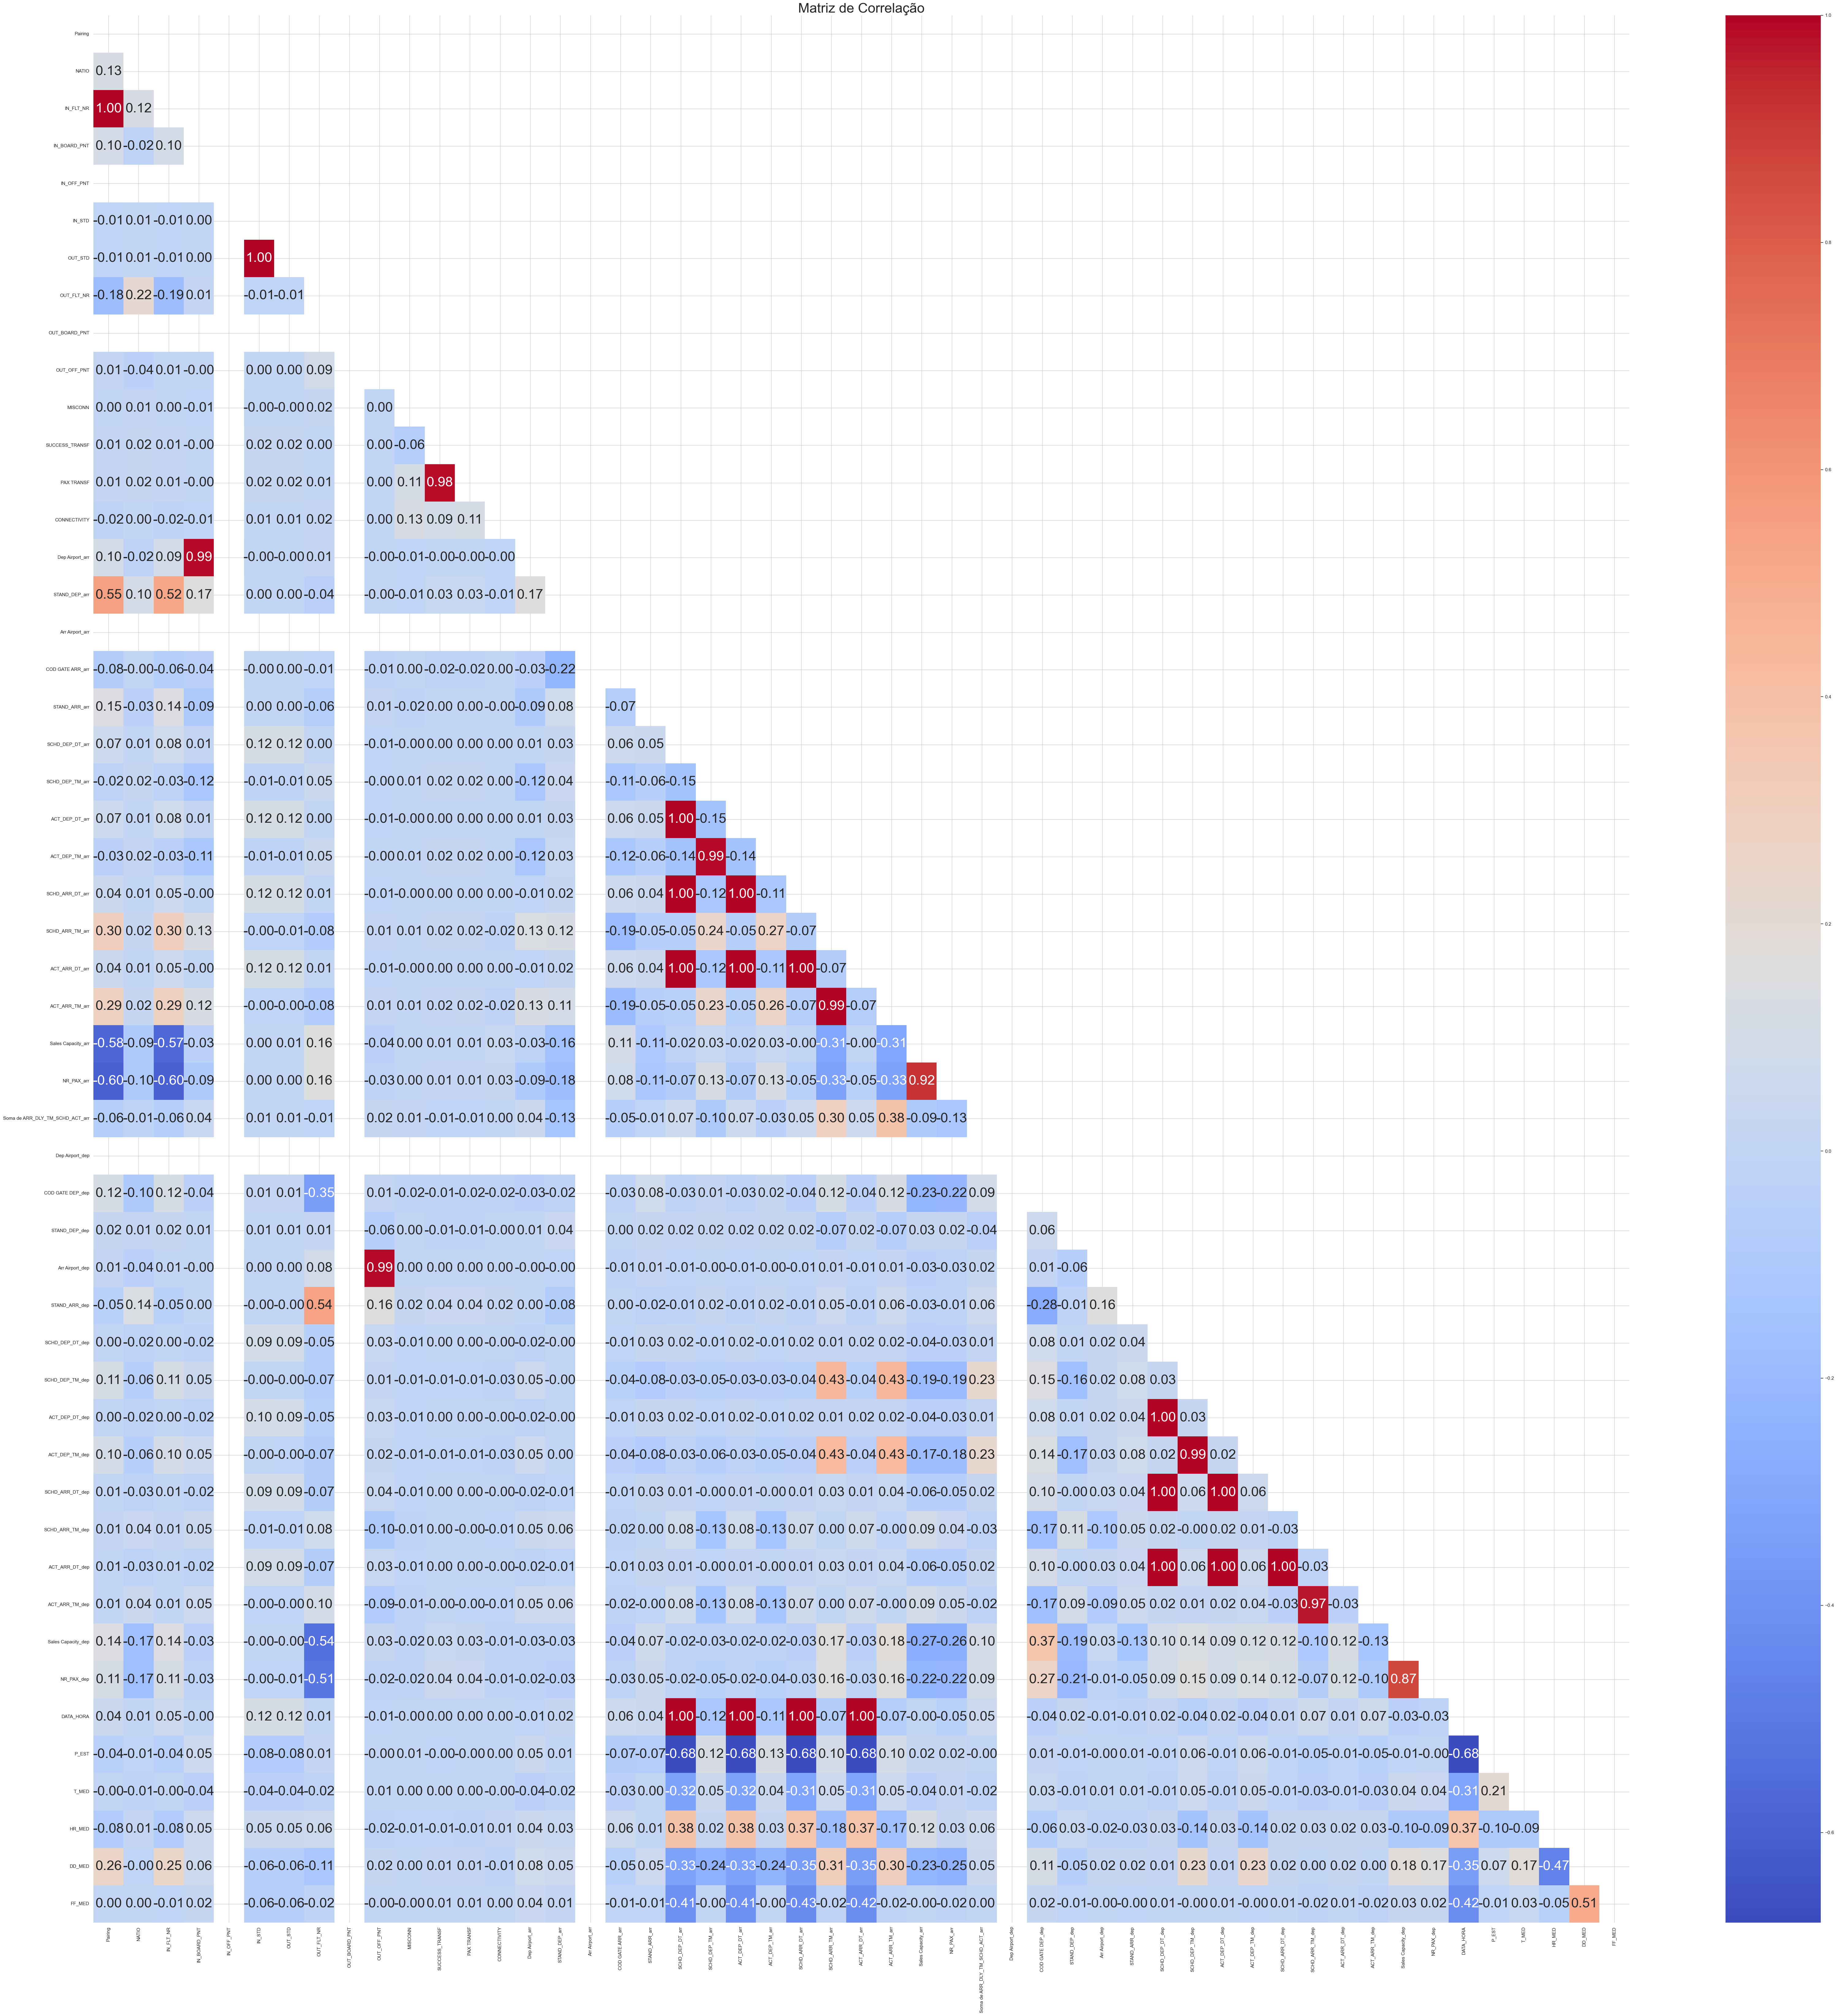

In [5]:
plt.figure(figsize=(66, 66))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', annot_kws={"size": 32})

plt.title('Matriz de Correlação', fontsize=32)
plt.tight_layout()
plt.show

In [ ]:
# Escolher o target que você quer analisar: "Atraso_Chegada" ou "Atraso_Partida"
target_corr = corr['MISCONN'].abs().sort_values(ascending=False)

# Definir limiar de correlação
threshold = 0.01
selected_features = target_corr[target_corr > threshold].index.tolist()

print(f'Selected {len(selected_features)} features com |corr| > {threshold}:')
print(target_corr[selected_features], "\n")

Selected 13 features com |corr| > 0.01:
MISCONN                            1.000000
CONNECTIVITY                       0.129638
PAX TRANSF                         0.109989
SUCCESS_TRANSF                     0.064471
OUT_FLT_NR                         0.020747
COD GATE DEP_dep                   0.020529
Sales Capacity_dep                 0.019267
STAND_ARR_dep                      0.018955
NR_PAX_dep                         0.015884
SCHD_ARR_TM_dep                    0.013733
NATIO                              0.013234
ACT_ARR_TM_dep                     0.012569
Soma de ARR_DLY_TM_SCHD_ACT_arr    0.010335
Name: MISCONN, dtype: float64 



In [6]:
# Escolher o target que você quer analisar: "Atraso_Chegada" ou "Atraso_Partida"
target_corr = corr['CONNECTIVITY'].abs().sort_values(ascending=False)

# Definir limiar de correlação
threshold = 0.02
selected_features = target_corr[target_corr > threshold].index.tolist()

print(f'Selected {len(selected_features)} features com |corr| > {threshold}:')
print(target_corr[selected_features], "\n")

Selected 11 features com |corr| > 0.02:
CONNECTIVITY          1.000000
MISCONN               0.129638
PAX TRANSF            0.112926
SUCCESS_TRANSF        0.090705
Sales Capacity_arr    0.032157
NR_PAX_arr            0.028683
ACT_DEP_TM_dep        0.027852
SCHD_DEP_TM_dep       0.027832
SCHD_ARR_TM_arr       0.021758
COD GATE DEP_dep      0.020845
ACT_ARR_TM_arr        0.020833
Name: CONNECTIVITY, dtype: float64 



In [7]:
# 1. Carregar os dados
# Substitua 'seus_dados.csv' pelo caminho do seu arquivo de dados

# 2. Conversão de tipos de dados

df_final_merge['SCHD_DEP'] = pd.to_datetime(df_final_merge['SCHD_DEP_DT_arr'] + ' ' + df_final_merge['SCHD_DEP_TM_arr'])
df_final_merge['ACT_DEP'] = pd.to_datetime(df_final_merge['ACT_DEP_DT_arr'] + ' ' + df_final_merge['ACT_DEP_TM_arr'])
df_final_merge['SCHD_ARR'] = pd.to_datetime(df_final_merge['SCHD_ARR_DT_dep'] + ' ' + df_final_merge['SCHD_ARR_TM_dep'])
df_final_merge['ACT_ARR'] = pd.to_datetime(df_final_merge['ACT_ARR_DT_dep'] + ' ' + df_final_merge['ACT_ARR_TM_dep'])


# 3. Cálculo de atrasos
df_final_merge['Atraso_Partida'] = (df_final_merge['ACT_DEP'] - df_final_merge['SCHD_DEP']).dt.total_seconds() / 60.0
df_final_merge['Atraso_Chegada'] = (df_final_merge['ACT_ARR'] - df_final_merge['SCHD_ARR']).dt.total_seconds() / 60.0


C:\Users\joaoc\AppData\Local\Temp\ipykernel_23032\4084536935.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_final_merge['SCHD_DEP'] = pd.to_datetime(df_final_merge['SCHD_DEP_DT_arr'] + ' ' + df_final_merge['SCHD_DEP_TM_arr'])
C:\Users\joaoc\AppData\Local\Temp\ipykernel_23032\4084536935.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_final_merge['ACT_DEP'] = pd.to_datetime(df_final_merge['ACT_DEP_DT_arr'] + ' ' + df_final_merge['ACT_DEP_TM_arr'])
C:\Users\joaoc\AppData\Local\Temp\ipykernel_23032\4084536935.py:8: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df

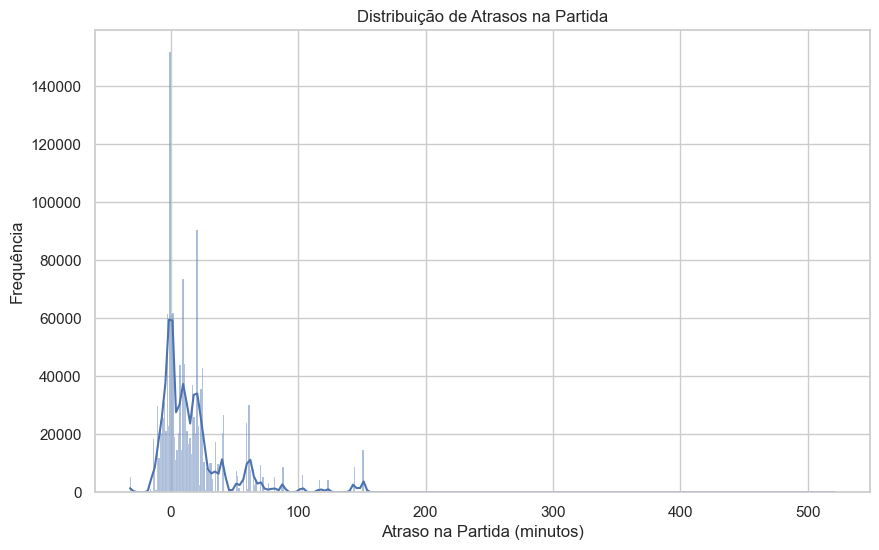

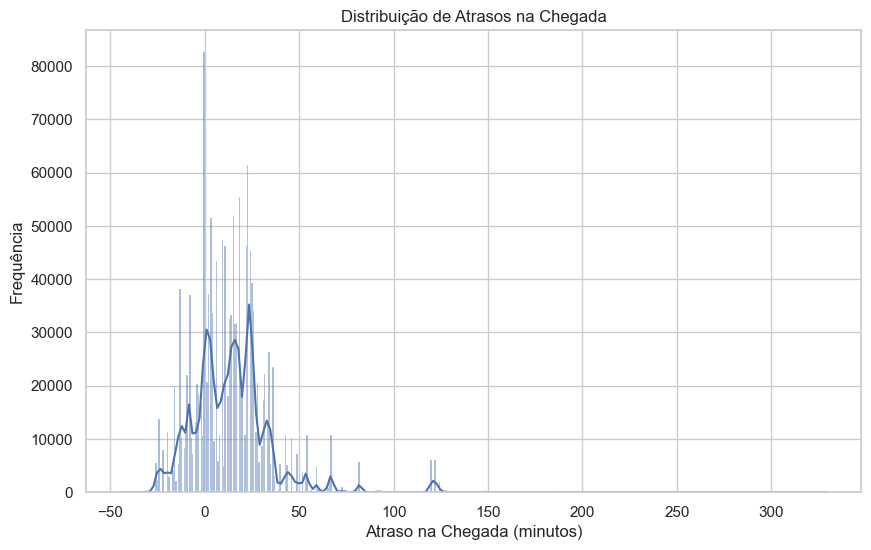

In [74]:
# Algumas Visualizações

# Distribuição de atrasos na partida
plt.figure(figsize=(10, 6))
sns.histplot(df_final_merge['Atraso_Partida'].dropna(), bins=500, kde=True)
plt.title('Distribuição de Atrasos na Partida')
plt.xlabel('Atraso na Partida (minutos)')
plt.ylabel('Frequência')
plt.show()

# Distribuição de atrasos na chegada
plt.figure(figsize=(10, 6))
sns.histplot(df_final_merge['Atraso_Chegada'].dropna(), bins=500, kde=True)
plt.title('Distribuição de Atrasos na Chegada')
plt.xlabel('Atraso na Chegada (minutos)')
plt.ylabel('Frequência')
plt.show()

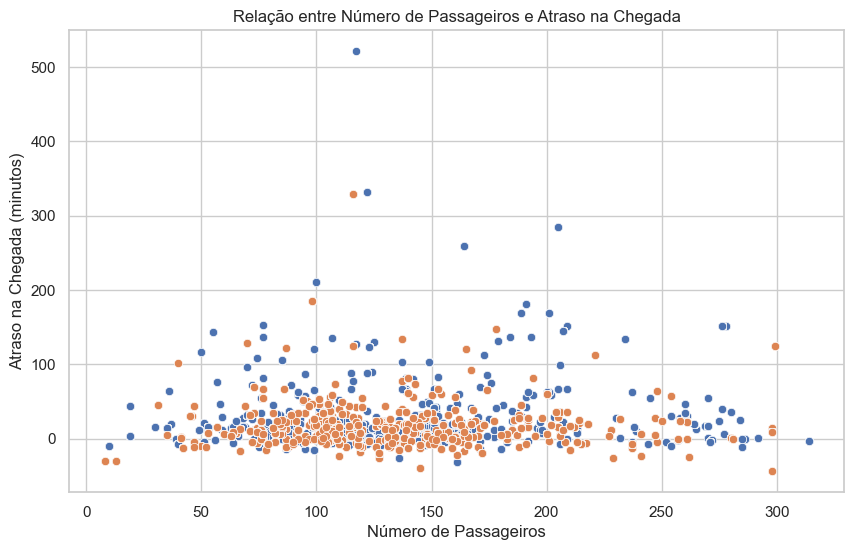

In [56]:
# 3. Relação entre número de passageiros e atrasos na chegada

plt.figure(figsize=(10, 6))
sns.scatterplot(x='NR_PAX_arr', y='Atraso_Partida', data=df_final_merge)
sns.scatterplot(x='NR_PAX_dep', y='Atraso_Chegada', data=df_final_merge)
plt.title('Relação entre Número de Passageiros e Atraso na Chegada')
plt.xlabel('Número de Passageiros')
plt.ylabel('Atraso na Chegada (minutos)')
plt.show()

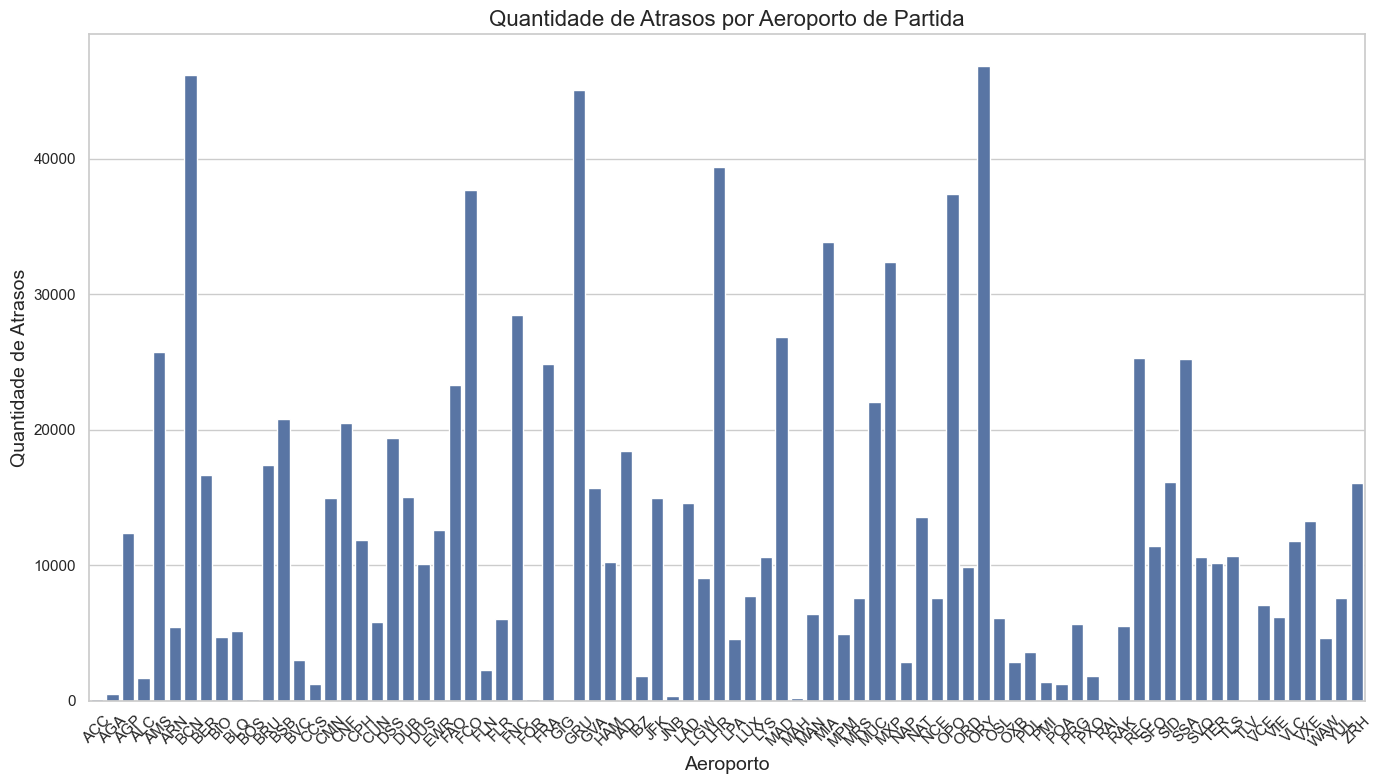

In [90]:
# 4. Quantidade de atrasos por aeroporto de partida
# Considerando atrasos positivos (>0)
df_dep_delays = df_final_merge[df_final_merge['DEP_DELAY_arr'] > 0].copy()
airport_delays = df_dep_delays.groupby('Dep Airport_arr')['DEP_DELAY_arr'].agg(['count', 'mean']).reset_index()
airport_delays.columns = ['Aeroporto', 'Quantidade de Atrasos', 'Atraso Médio (min)']

plt.figure(figsize=(14, 8))
sns.barplot(x='Aeroporto', y='Quantidade de Atrasos', data=airport_delays)
plt.title('Quantidade de Atrasos por Aeroporto de Partida', fontsize=16)
plt.xlabel('Aeroporto', fontsize=14)
plt.ylabel('Quantidade de Atrasos', fontsize=14)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

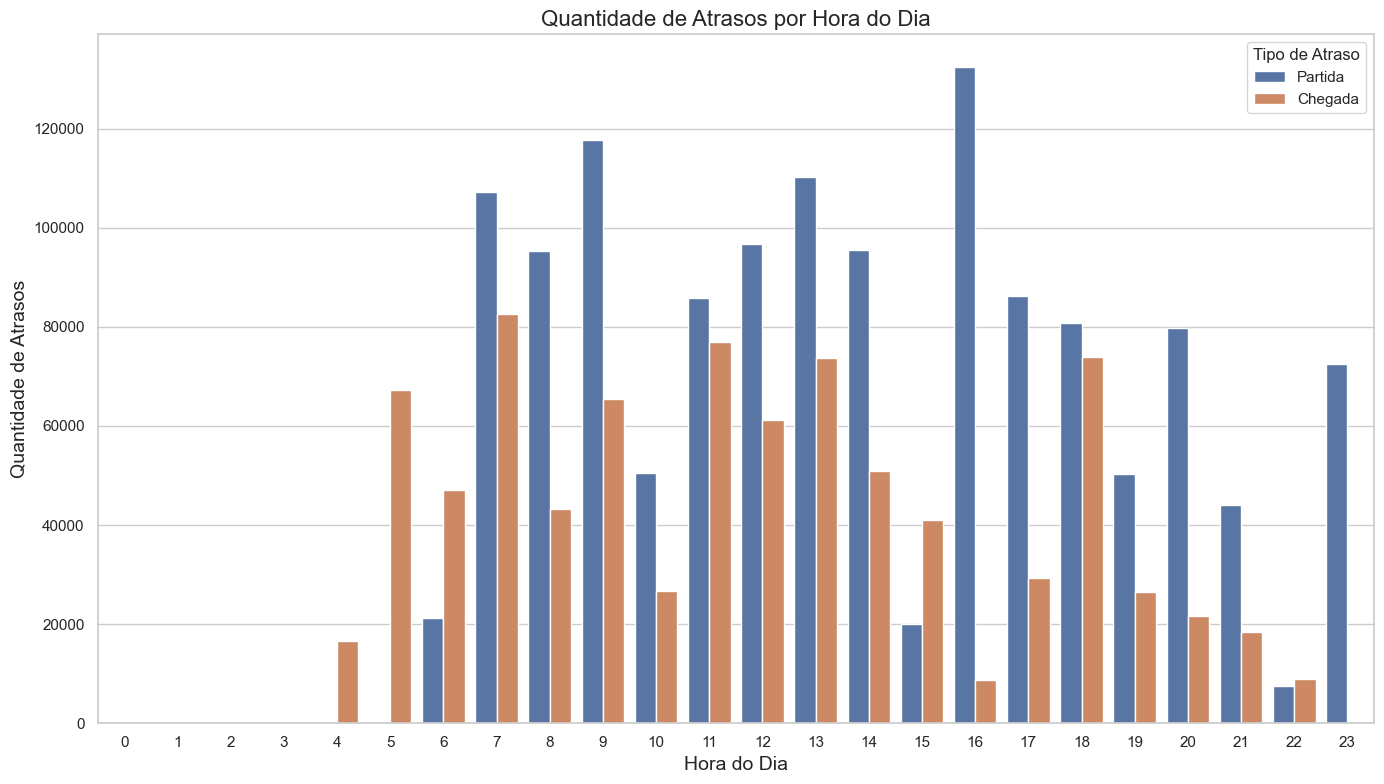

In [92]:
# 6. Altura do dia com mais atrasos
# Combinando atrasos de chegada e partida por hora
df_hour_delays = pd.DataFrame()
if 'HOUR_arr' in df_final_merge.columns and not df_final_merge['HOUR_arr'].isna().all():
    df_hour_delays_arr = df_final_merge[df_final_merge['ARR_DELAY_arr'] > 0].groupby('HOUR_arr')['ARR_DELAY_arr'].count().reset_index()
    df_hour_delays_arr.columns = ['Hora', 'Quantidade de Atrasos']
    df_hour_delays_arr['Tipo'] = 'Chegada'
    df_hour_delays = pd.concat([df_hour_delays, df_hour_delays_arr])

if 'HOUR_dep' in df_final_merge.columns and not df_final_merge['HOUR_dep'].isna().all():
    df_hour_delays_dep = df_final_merge[df_final_merge['DEP_DELAY_dep'] > 0].groupby('HOUR_dep')['DEP_DELAY_dep'].count().reset_index()
    df_hour_delays_dep.columns = ['Hora', 'Quantidade de Atrasos']
    df_hour_delays_dep['Tipo'] = 'Partida'
    df_hour_delays = pd.concat([df_hour_delays, df_hour_delays_dep])

if not df_hour_delays.empty:
    plt.figure(figsize=(14, 8))
    sns.barplot(x='Hora', y='Quantidade de Atrasos', hue='Tipo', data=df_hour_delays)
    plt.title('Quantidade de Atrasos por Hora do Dia', fontsize=16)
    plt.xlabel('Hora do Dia', fontsize=14)
    plt.ylabel('Quantidade de Atrasos', fontsize=14)
    plt.legend(title='Tipo de Atraso')
    plt.tight_layout()
    plt.show()

- da pressão atmosférica média ao nível da estação - P_EST - (hPa);
- da temperatura média do ar a 1,5 m - T_MED - em graus Celsius (°C);
- da humidade relativa média - HR_MED - em percentagem (%);
- do rumo médio do vento - DD_MED - em graus a partir do Norte geográfico (°);
- da intensiddde média do vento - FF_MED - em metros por segundo (m/s).

Foi constatado que alguns registos têm por defeito o valor 990 em caso de inteiro e 990.0 em caso de float como representação de erro ou valor omisso


In [10]:
weather_cols = ['P_EST', 'T_MED', 'HR_MED', 'DD_MED', 'FF_MED']

# Substituir valores -990/-990.0 pela moda em cada coluna meteorológica
for col in weather_cols:
    moda = df_final_merge.loc[df_final_merge[col] != -990, col].mode().iloc[0]
    df_final_merge[col] = df_final_merge[col].replace([-990, -990.0], moda)

In [ ]:
for col in weather_cols:
    plt.figure(figsize=(12, 8))
    plt.hexbin(df_final_merge[col], df_final_merge['Atraso_Chegada'],
               gridsize=50, cmap='Blues', mincnt=1)
    plt.colorbar(label='Contagem')
    plt.title(f'Hexbin: {col} vs Atraso na Chegada', fontsize=16)
    plt.xlabel(col, fontsize=14)
    plt.ylabel('Atraso na Chegada (minutos)', fontsize=14)
    plt.grid(True)
    plt.show()

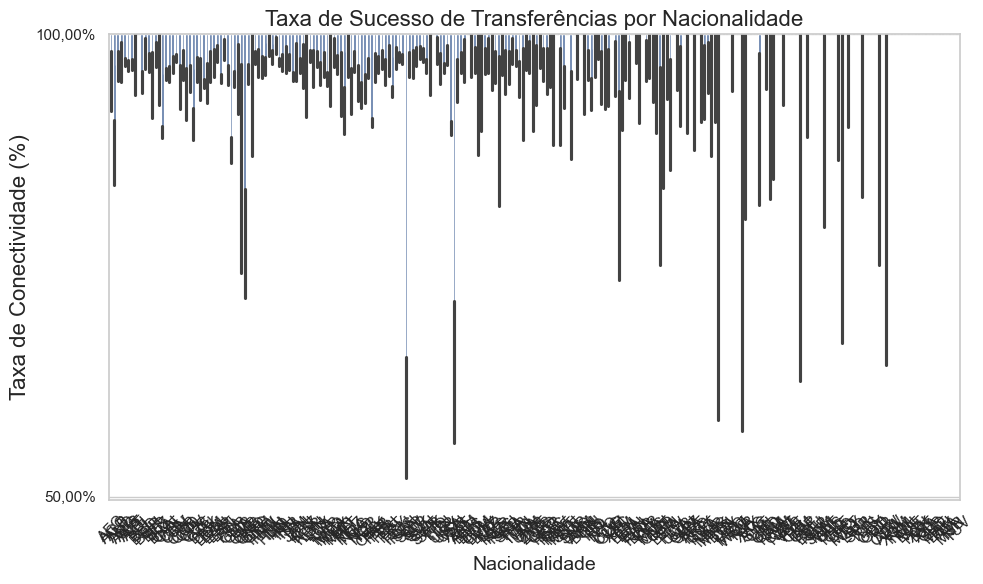

In [82]:
# 7.2 Taxa de sucesso de transferências
plt.figure(figsize=(10, 6))
sns.barplot(x='NATIO', y='CONNECTIVITY', data=df_final_merge)
plt.title('Taxa de Sucesso de Transferências por Nacionalidade', fontsize=16)
plt.xlabel('Nacionalidade', fontsize=14)
plt.ylabel('Taxa de Conectividade (%)', fontsize=16)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Seleção de registos a Treinar**

**SPLIT FOR TRAINING**

In [ ]:
# Split data into train/test for the current chunk

path = "./dados_VOO_IPMA.csv"

# Output files
train_output_file = "./dados_processados_treino.csv"
test_output_file = "./dados_processados_teste.csv"

df = pd.read_csv(path, delimiter=',')

if not df.empty:
    # Split data (80% train, 20% test)
    df_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
    
# Remove output files if they exist to start fresh
if os.path.exists(train_output_file):
    os.remove(train_output_file)
    print(f"Ficheiro de treino anterior removido: {train_output_file}")
if os.path.exists(test_output_file):
    os.remove(test_output_file)
    print(f"Ficheiro de teste anterior removido: {test_output_file}")

# Save to files
df_train.to_csv(train_output_file, index=False)
df_test.to_csv(test_output_file, index=False)

## 4. Métodos de Balanceamento + Treino do Modelo

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import StandardScaler
# *** MODIFIED: Import SMOTE instead of RandomUnderSampler ***
from imblearn.over_sampling import SMOTE 
import joblib
import time
import os

# --- Configuration ---
# Input file (generated by preprocess_split_v2.py)
train_file = "./dados_processados_treino.csv"

# Target variable
target_column = "MISCONN"

# Model and Scaler files to save
model_file = "./final_model_smote.joblib" # Renamed output file
scaler_file = "./final_scaler_smote.joblib" # Renamed output file

# Batch processing parameters (if train_file is still too large)
use_batches = False # Set to True if dados_processados_treino.csv might exceed memory
batch_size = 500000 # Adjust if using batches

# SMOTE parameters (can be adjusted)
smote_k_neighbors = 5 # Default is 5, adjust if needed based on minority class size

# --- Helper Functions ---
def check_file_exists(filepath):
    if not os.path.exists(filepath):
        print(f"ERRO FATAL: Ficheiro de treino não encontrado: {filepath}")
        return False
    return True

# --- Main Training Pipeline ---
def run_final_training():
    start_time = time.time()

    if not check_file_exists(train_file):
        return

    # Initialize Model, Scaler
    model = SGDClassifier(random_state=42, loss='log_loss') # Using log_loss for probability estimates if needed later
    scaler = StandardScaler()
    # *** MODIFIED: Initialize SMOTE ***
    # Ensure k_neighbors is less than the smallest class count in a batch
    # We might need to adjust k_neighbors dynamically or handle errors if a batch has too few minority samples
    smote = SMOTE(random_state=42, k_neighbors=smote_k_neighbors) 
    
    classes = np.array([0, 1]) # Assuming binary classification
    first_batch = True
    total_rows_processed = 0

    print(f"Iniciando treino final com {train_file}...")
    print(f"Usando SMOTE para oversampling.")

    try:
        if use_batches:
            print(f"Modo Batch Ativado. Tamanho do batch: {batch_size}")
            # Process in chunks if the training file is too large
            for i, df_train_chunk in enumerate(pd.read_csv(train_file, chunksize=batch_size, low_memory=False)):
                batch_start_time = time.time()
                print(f"\n--- Processando Batch de Treino {i+1} --- Shape: {df_train_chunk.shape}")
                total_rows_processed += len(df_train_chunk)

                # Define Features (X) and Target (y)
                numeric_cols = df_train_chunk.select_dtypes(include=np.number).columns.tolist()
                feature_columns = [col for col in numeric_cols if col != target_column]
                
                if not feature_columns:
                    print("  - AVISO: Nenhuma feature numérica (não-target) encontrada no batch. Ignorando.")
                    continue
                    
                X_chunk = df_train_chunk[feature_columns]
                y_chunk = df_train_chunk[target_column]
                print(f"  - Features selecionadas: {feature_columns}")

                # *** MODIFIED: Balanceamento (SMOTE) ***
                print(f"  - Distribuição antes do SMOTE: {y_chunk.value_counts().to_dict()}")
                try:
                    # Check if minority class has enough samples for k_neighbors
                    minority_count = y_chunk.value_counts().min()
                    if y_chunk.nunique() >= 2 and minority_count > 0:
                        # Adjust k_neighbors if it's >= minority_count
                        current_k = min(smote_k_neighbors, minority_count - 1) if minority_count > 1 else 1
                        if current_k != smote.k_neighbors:
                             print(f"    - Ajustando k_neighbors do SMOTE para {current_k} neste batch.")
                             smote_batch = SMOTE(random_state=42, k_neighbors=current_k)
                        else:
                             smote_batch = smote # Use the original smote object
                        
                        if current_k >= 1:
                            X_resampled, y_resampled = smote_batch.fit_resample(X_chunk, y_chunk)
                            print(f"  - Distribuição após SMOTE: {y_resampled.value_counts().to_dict()}")
                        else:
                            print("  - AVISO: Classe minoritária com apenas 1 amostra. SMOTE não aplicável. Usando dados originais.")
                            X_resampled, y_resampled = X_chunk, y_chunk
                    else:
                        print("  - AVISO: SMOTE não aplicável (menos de 2 classes ou classe minoritária vazia).")
                        X_resampled, y_resampled = X_chunk, y_chunk
                except ValueError as ve:
                    print(f"  - AVISO: Erro no SMOTE: {ve}. Usando dados originais do batch.")
                    X_resampled, y_resampled = X_chunk, y_chunk

                if X_resampled.empty:
                    print("  - AVISO: Batch vazio após SMOTE. Ignorando.")
                    continue

                # Scaling
                if first_batch:
                    X_scaled = scaler.fit_transform(X_resampled)
                    print(f"  - Scaler ajustado no primeiro batch.")
                else:
                    try:
                        # Ensure columns are in the order the scaler expects
                        if hasattr(scaler, "feature_names_in_"):
                             X_resampled_ordered = X_resampled[scaler.feature_names_in_]
                        else:
                             X_resampled_ordered = X_resampled # Proceed with caution
                        X_scaled = scaler.transform(X_resampled_ordered)
                        print("  - Batch escalado com scaler pré-ajustado.")
                    except Exception as scale_err:
                        print(f"  - ERRO durante o scaling: {scale_err}. Ignorando batch.")
                        continue

                # Treino Incremental
                if y_resampled.empty:
                    print("  - AVISO: y_resampled vazio antes do treino. Ignorando batch.")
                    continue
                    
                if first_batch:
                    try:
                        model.partial_fit(X_scaled, y_resampled, classes=classes)
                        first_batch = False
                        print("  - Modelo treinado no primeiro batch (com classes).")
                    except ValueError as fit_err:
                        print(f"  - ERRO no primeiro partial_fit: {fit_err}. Ignorando batch.")
                        continue
                else:
                    try:
                        model.partial_fit(X_scaled, y_resampled)
                        print("  - Modelo atualizado com o batch.")
                    except ValueError as fit_err:
                        print(f"  - ERRO no partial_fit subsequente: {fit_err}. Ignorando batch.")
                        continue
                        
                batch_time = time.time() - batch_start_time
                print(f"  - Batch {i+1} concluído em {batch_time:.2f} segundos.")

        else: # Not using batches, process the whole file
            print("Modo Batch Desativado. Lendo ficheiro de treino completo...")
            df_train = pd.read_csv(train_file, low_memory=False)
            total_rows_processed = len(df_train)
            print(f"Ficheiro lido. Shape: {df_train.shape}")

            # Define Features (X) and Target (y)
            numeric_cols = df_train.select_dtypes(include=np.number).columns.tolist()
            feature_columns = [col for col in numeric_cols if col != target_column]
            
            if not feature_columns:
                 print("ERRO: Nenhuma feature numérica (não-target) encontrada. Abortando.")
                 return
                 
            X = df_train[feature_columns]
            y = df_train[target_column]
            print(f"  - Features selecionadas: {feature_columns}")

            # *** MODIFIED: Balanceamento (SMOTE) ***
            print(f"  - Distribuição antes do SMOTE: {y.value_counts().to_dict()}")
            try:
                minority_count = y.value_counts().min()
                if y.nunique() >= 2 and minority_count > 0:
                    current_k = min(smote_k_neighbors, minority_count - 1) if minority_count > 1 else 1
                    if current_k != smote.k_neighbors:
                         print(f"    - Ajustando k_neighbors do SMOTE para {current_k}.")
                         smote_final = SMOTE(random_state=42, k_neighbors=current_k)
                    else:
                         smote_final = smote
                         
                    if current_k >= 1:
                        X_resampled, y_resampled = smote_final.fit_resample(X, y)
                        print(f"  - Distribuição após SMOTE: {y_resampled.value_counts().to_dict()}")
                    else:
                        print("  - AVISO: Classe minoritária com apenas 1 amostra. SMOTE não aplicável. Usando dados originais.")
                        X_resampled, y_resampled = X, y
                else:
                    print("  - AVISO: SMOTE não aplicável (menos de 2 classes ou classe minoritária vazia).")
                    X_resampled, y_resampled = X, y
            except ValueError as ve:
                 print(f"  - AVISO: Erro no SMOTE: {ve}. Usando dados originais.")
                 X_resampled, y_resampled = X, y
                 
            if X_resampled.empty:
                print("ERRO: Nenhum dado restante após SMOTE. Abortando.")
                return

            # Scaling
            print("Ajustando e aplicando scaler...")
            X_scaled = scaler.fit_transform(X_resampled)

            # Treino
            print("Treinando modelo...")
            model.fit(X_scaled, y_resampled)
            first_batch = False # Mark as trained

        # Salvar Modelo e Scaler Finais
        if not first_batch: # Check if any training actually happened
            joblib.dump(model, model_file)
            joblib.dump(scaler, scaler_file)
            print(f"\nModelo final salvo em: {model_file}")
            print(f"Scaler final salvo em: {scaler_file}")
        else:
            print("\nAVISO: Nenhum treino realizado (possivelmente devido a batches vazios ou erros). Modelo/Scaler não foram salvos.")

    except Exception as e:
        print(f"\nERRO INESPERADO durante o treino final: {e}")
        import traceback
        traceback.print_exc()
    finally:
        end_time = time.time()
        total_time = end_time - start_time
        print(f"\n--- Treino Concluído ---")
        print(f"Total de linhas processadas do ficheiro de treino: {total_rows_processed}")
        print(f"Tempo total de execução do treino: {total_time:.2f} segundos.")

# --- Executar Pipeline ---
if __name__ == "__main__":
    run_final_training()

## 5. Avaliação do Modelo

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import joblib
import time
import os

# --- Configuration ---
# Input file (generated by preprocess_split_v2.py)
test_file = "./dados_processados_teste.csv"

# Model and Scaler files to load (saved by train_final_smote_v2.py)
model_file = "./final_model_smote.joblib" # Ensure this matches the training output
scaler_file = "./final_scaler_smote.joblib" # Ensure this matches the training output

# Target variable
target_column = "MISCONN"
expected_classes = [0, 1] # Define the valid classes for the target

# Batch processing parameters (if test_file is too large)
use_batches = False # Set to True if dados_processados_teste.csv might exceed memory
batch_size = 500000 # Adjust if using batches

# --- Helper Functions ---
def check_file_exists(filepath):
    if not os.path.exists(filepath):
        print(f"ERRO FATAL: Ficheiro não encontrado: {filepath}")
        return False
    return True

# --- Main Evaluation Pipeline ---
def run_final_evaluation():
    start_time = time.time()

    # 1. Check for essential files (Model, Scaler, Test Data)
    if not all(check_file_exists(f) for f in [model_file, scaler_file, test_file]):
        print("ERRO: Ficheiros essenciais (modelo, scaler, dados de teste) em falta. Abortando avaliação.")
        return

    # 2. Load Model and Scaler
    try:
        model = joblib.load(model_file)
        scaler = joblib.load(scaler_file)
        print(f"Modelo carregado de: {model_file}")
        print(f"Scaler carregado de: {scaler_file}")
    except Exception as e:
        print(f"ERRO ao carregar modelo ou scaler: {e}. Abortando avaliação.")
        return

    # Lists to store results
    all_y_true = []
    all_y_pred = []
    total_rows_processed = 0

    print(f"Iniciando avaliação final com {test_file}...")

    try:
        if use_batches:
            print(f"Modo Batch Ativado. Tamanho do batch: {batch_size}")
            # Process in chunks if the test file is too large
            for i, df_test_chunk in enumerate(pd.read_csv(test_file, chunksize=batch_size, low_memory=False)):
                batch_start_time = time.time()
                print(f"\n--- Processando Batch de Teste {i+1} --- Shape: {df_test_chunk.shape}")
                total_rows_processed += len(df_test_chunk)

                # *** ADDED: Check if target column exists early ***
                if target_column not in df_test_chunk.columns:
                    print(f"  - ERRO: Coluna target ", target_column, " não encontrada neste batch. Ignorando.")
                    continue
                    
                # *** ADDED: Check if dataframe is empty early ***
                if df_test_chunk.empty:
                    print("  - AVISO: Batch de teste vazio. Ignorando.")
                    continue

                # Define Features (X) and Target (y)
                numeric_cols = df_test_chunk.select_dtypes(include=np.number).columns.tolist()
                feature_columns = [col for col in numeric_cols if col != target_column]
                
                # Check if scaler expects these features
                expected_features = []
                if hasattr(scaler, "feature_names_in_"):
                    expected_features = scaler.feature_names_in_
                    missing_features = set(expected_features) - set(feature_columns)
                    if missing_features:
                        print(f"  - AVISO: Features esperadas pelo scaler em falta no teste: {missing_features}. Adicionando como 0.")
                        for mf in missing_features:
                            df_test_chunk[mf] = 0
                        feature_columns = list(expected_features)
                    else:
                        feature_columns = [col for col in expected_features if col in feature_columns]
                elif not feature_columns:
                    print("  - AVISO: Nenhuma feature numérica válida encontrada e scaler sem feature_names_in_. Ignorando batch.")
                    continue
                else:
                    print(f"  - AVISO: Scaler sem feature_names_in_. Usando features encontradas: {feature_columns}")

                if not feature_columns:
                    print("  - AVISO: Nenhuma feature final encontrada no batch após verificação do scaler. Ignorando.")
                    continue
                    
                X_test_chunk = df_test_chunk[feature_columns]
                # *** ADDED: Check target column again before access ***
                if target_column not in df_test_chunk.columns:
                     print(f"  - ERRO: Coluna target ", target_column, " desapareceu antes da seleção de y. Ignorando batch.")
                     continue
                y_test_chunk = df_test_chunk[target_column]
                print(f"  - Features selecionadas: {feature_columns}")

                # Scaling
                try:
                    X_test_chunk_ordered = X_test_chunk[expected_features] if expected_features else X_test_chunk
                    X_test_scaled = scaler.transform(X_test_chunk_ordered)
                    print("  - Batch de teste escalado.")
                except Exception as scale_err:
                    print(f"  - ERRO durante o scaling do teste: {scale_err}. Ignorando batch.")
                    continue

                # Prediction
                try:
                    y_pred_chunk = model.predict(X_test_scaled)
                    print("  - Previsões realizadas no batch de teste.")
                except Exception as pred_err:
                    print(f"  - ERRO durante a previsão: {pred_err}. Ignorando batch.")
                    continue

                # Accumulate results
                all_y_true.extend(y_test_chunk.tolist())
                all_y_pred.extend(y_pred_chunk.tolist())

                batch_time = time.time() - batch_start_time
                print(f"  - Batch {i+1} concluído em {batch_time:.2f} segundos.")

        else: # Not using batches, process the whole file
            print("Modo Batch Desativado. Lendo ficheiro de teste completo...")
            df_test = pd.read_csv(test_file, low_memory=False)
            total_rows_processed = len(df_test)
            print(f"Ficheiro lido. Shape: {df_test.shape}")

            # *** ADDED: Check if target column exists ***
            if target_column not in df_test.columns:
                print(f"ERRO: Coluna target ", target_column, " não encontrada no ficheiro de teste. Abortando.")
                return
                
            # *** ADDED: Check if dataframe is empty ***
            if df_test.empty:
                print("ERRO: Ficheiro de teste vazio. Abortando.")
                return

            # Define Features (X) and Target (y)
            numeric_cols = df_test.select_dtypes(include=np.number).columns.tolist()
            feature_columns = [col for col in numeric_cols if col != target_column]
            
            # Check if scaler expects these features
            expected_features = []
            if hasattr(scaler, "feature_names_in_"):
                 expected_features = scaler.feature_names_in_
                 missing_features = set(expected_features) - set(feature_columns)
                 if missing_features:
                      print(f"  - AVISO: Features esperadas pelo scaler em falta no teste: {missing_features}. Adicionando como 0.")
                      for mf in missing_features:
                           df_test[mf] = 0
                      feature_columns = list(expected_features)
                 else:
                      feature_columns = [col for col in expected_features if col in feature_columns]
            elif not feature_columns:
                 print("ERRO: Nenhuma feature numérica válida encontrada e scaler sem feature_names_in_. Abortando.")
                 return
            else:
                 print(f"  - AVISO: Scaler sem feature_names_in_. Usando features encontradas: {feature_columns}")

            if not feature_columns:
                 print("ERRO: Nenhuma feature final encontrada após verificação do scaler. Abortando.")
                 return
                 
            X_test = df_test[feature_columns]
            # *** ADDED: Check target column again before access ***
            if target_column not in df_test.columns:
                 print(f"ERRO: Coluna target ", target_column, " desapareceu antes da seleção de y. Abortando.")
                 return
            y_test = df_test[target_column]
            print(f"  - Features selecionadas: {feature_columns}")

            # Scaling
            print("Aplicando scaler...")
            X_test_ordered = X_test[expected_features] if expected_features is not None and len(expected_features) > 0 else X_test
            X_test_scaled = scaler.transform(X_test_ordered)

            # Prediction
            print("Realizando previsões...")
            y_pred = model.predict(X_test_scaled)

            all_y_true = y_test.tolist()
            all_y_pred = y_pred.tolist()

        # Calculate Overall Metrics
        print("\n--- Avaliação Geral Concluída ---")
        if not all_y_true:
            print("AVISO: Nenhum dado foi avaliado. Verifique o ficheiro de teste e o pipeline.")
        else:
            accuracy = accuracy_score(all_y_true, all_y_pred)
            print(f"Total de linhas avaliadas: {len(all_y_true)}")
            print(f"Acurácia Geral: {accuracy:.4f}")
            
            print("\nMatriz de Confusão Geral:")
            cm_labels = sorted(list(set(all_y_true) | set(all_y_pred)))
            # Ensure labels are [0, 1] if possible for standard confusion matrix
            if set(cm_labels).issubset(set(expected_classes)):
                 cm_labels = expected_classes
            print(confusion_matrix(all_y_true, all_y_pred, labels=cm_labels))
            
            print("\nRelatório de Classificação Geral:")
            # Ensure target_names match the labels order
            target_names = [f"Classe {l}" for l in cm_labels]
            print(classification_report(all_y_true, all_y_pred, labels=cm_labels, target_names=target_names, zero_division=0))

    except Exception as e:
        print(f"\nERRO INESPERADO durante a avaliação final: {e}")
        import traceback
        traceback.print_exc()
    finally:
        end_time = time.time()
        total_time = end_time - start_time
        print(f"\n--- Avaliação Concluída ---")
        print(f"Total de linhas processadas do ficheiro de teste: {total_rows_processed}")
        print(f"Tempo total de execução da avaliação: {total_time:.2f} segundos.")

# --- Executar Pipeline de Avaliação ---
if __name__ == "__main__":
    run_final_evaluation()